# Canopy interception: $E_0$, $E_i$ and $\Delta S_i/\Delta t$ – hourly, cloud forest (CF), agroforestry (AF) and conventional agriculture (CA)

Each plot is run **independently**: it has its own data file(s), column names, wind and parameters.
List the plots to run in `PLOTS_TO_RUN`. Results are written to `outputs_v2/` (the older outputs in this
folder are kept).

**Method**

- **$E_0$** – potential evaporation from a fully wetted canopy: Penman–Monteith with $r_s = 0$
  (FAO-56 hourly procedure). $r_a$ from a neutral logarithmic wind profile over the canopy ($z_m = z_h$).
  - Wind for both plots: ECMWF 100 m (Open-Meteo API), the same data set at CF ($h$ = 20 m, drone: canopy
    13–24 m), AF ($h$ = 2 m) and CA (maize, $h$ = 2.1 m).
  - Sensitivity (AF): Tempest anemometer at 5.5 m.
- **$E_i$, $S_i$, $P_e$** – hourly canopy bucket of capacity $S_{max}$ in the FLEX-Topo order
  (Eqs. 6.4–6.6), driven by $In = P + F$ only. No evaporation in hours with rain ($P > 0$);
  evaporation during rain (Gash, 1979) is a sensitivity case.
- **Gauges** – measured $TF + SF$ are *not* model inputs. They are compared with the modelled
  $P_e$: `error` $= (TF+SF)_{meas} - P_e$, and $S_{wb} = S_0 + \sum (In - TF - SF - E_i)$ is the storage
  the gauges imply.
- **CA** – no throughfall/stemflow gauges: the bucket gives $E_i$, $P_e$ and $S_i$ only (`error`, $S_{wb}$ = NaN).
  The maize was post-harvest (drying in the field) and was cut down on 13 October; the run covers the entire period.
- Closure every hour: $In = E_i + P_e + \Delta S_i$.
- **Events** – an event ends after a dry period longer than the canopy drying time (p90, per plot)
  and a dry canopy. The drying time is the time the cumulative $E_0$ needs to remove the storage left
  after a wet spell, so night hours count as time without drying.
- **Sensitivity** – explicit $S_{max}$ values (report ranges), canopy height $h$ (CF 13–24 m, drone),
  evaporation during rain (Gash), minimum dry period, and the Tempest wind at the AF.

**Structure**

0. Settings – the only cell to edit
1. Imports
2. FAO-56 building blocks + $r_a$
3. `e0_hourly` + FAO-56 Example 19 check
4. Canopy bucket (FLEX-Topo) + smoke test
5. Drying time and event delineation
6. Data loading (per plot)
7. Run each plot – daily totals, events, hourly table
8. Sensitivity analysis
9. Figures
10. Export (incl. terms for the water-balance script)
11. Checks

## 0. Settings – edit only this cell

In [126]:
# ---------------- which plots to run (one or both, each independently) ----------------
PLOTS_TO_RUN = ["CF", "AF", "CA"]
TIME_COL = "Timestamp"            # local time (UTC-6), start of each hourly interval

# ---------------- input files per plot ----------------
# several files per plot are joined on the timestamp
DATA_FILES = {
    "CF": ["loggers_20261002-20261017_1h(5).csv"],
    "AF": ["loggers_20261002-20261017_1h(5).csv"],
    "CA": ["loggers_20261002-20261017_1h(5).csv"],   # LOGTAG-CA / Mayfly2_CA columns only in this file
}

# ---------------- optional derived columns (e.g. a single tipping-bucket gutter) ----------------
# new_column: (raw volume column [mL], effective gutter area [cm2])  ->  depth [mm]
# example for CF-1 only:  "TF_CF1_mm": ("Mayfly3_CF-1-TF_TippingBucket7_Volume", 2540.29648)
DERIVED_TF = {
    "CF": {},
    "AF": {},
    "CA": {},
}

# ---------------- throughfall from one gauge only, in given periods ----------------
# (start, end, column): end is exclusive (timestamps = start of the hour)
TF_OVERRIDE = {
    "CF": [("2026-10-11 00:00", "2026-10-12 12:00", "HOBO_CF-2-TF_Throughfall_mm")],   # CF-2 only
    "AF": [],
    "CA": [],
}

# ---------------- ECMWF wind (Open-Meteo API) ----------------
OM_URL = "https://archive-api.open-meteo.com/v1/archive"   # latest days missing? use
                                                           # "https://historical-forecast-api.open-meteo.com/v1/forecast"

# ---------------- fog input (CF only) ----------------
FOG_SOURCE      = "fiesta"        # "fiesta" | "trap" | None
FIESTA_FILE     = "/Users/victoria/Desktop/guatemala/codeWB/fog/fog_hourly_output.csv"
FIESTA_TIME_COL = "Timestamp"     # "2026-10-02 00:00:00-06:00"
FIESTA_COL      = "fiesta_fog_mm" # canopy fog deposition [mm h-1]
FOG_ONLY_WITHOUT_RAIN = True      # fog added only in hours with P = 0 (avoids double counting with rain)

# ---------------- site parameters ----------------
PARAMS = {
    "CF": dict(
        name="Cloud forest",
        latitude_deg=15.369, longitude_deg=90.345,   # longitude in deg WEST
        elevation_m=1669, lz_deg=90,                 # UTC-6 standard meridian
        albedo=0.13,                                 # Giambelluca et al. (1997)
        canopy_height_m=20.0,                        # drone: canopy 13-24 m
        wind_source="ecmwf", wind_height_m=100.0,    # ECMWF 100 m wind
        om_lat=15.3644, om_lon=-90.3441,             # point for the ECMWF wind
        S_max_mm=3.5,                                # Holwerda et al. (2010); range 1.2-4.0 mm
        fog=True,
    ),
    "AF": dict(
        name="Agroforestry",
        latitude_deg=15.374, longitude_deg=90.351,
        elevation_m=1422, lz_deg=90,
        albedo=0.15,                                 # between forest and farmland (Giambelluca et al., 1997)
        canopy_height_m=1.5,                         # crop height
        wind_source="ecmwf", wind_height_m=100.0,    # baseline: same data set as CF
        om_lat=15.374, om_lon=-90.351,               # point for the ECMWF wind
        wind_alt=dict(source="column", height_m=5.5, label="Tempest, 5.5 m"),   # sensitivity
        S_max_mm=1.2,                                # trees + crop, Wu et al. (2026); range 0.5-2.5 mm
        fog=False,
    ),
    "CA": dict(
        name="Conventional agriculture",
        latitude_deg=15.366104, longitude_deg=90.354231,   # deg WEST (check: 15.37 N like the other plots)
        elevation_m=1660, lz_deg=90,
        albedo=0.17,                                 # actively farmed fields 0.170-0.176 (Giambelluca et al., 1997)
        canopy_height_m=2.1,                         # measured maize height
        wind_source="ecmwf", wind_height_m=100.0,    # same data set as CF and AF
        om_lat=15.366104, om_lon=-90.354231,         # point for the ECMWF wind
        S_max_mm=0.5,                                # drying maize: 0.2 LAI (Kozak et al., 2007) = crop-only bound of AF
        P_gapfill=("HOBO_Rain_OpenSky_mm", 0.92),    # hours without CA rain: CF open-sky gauge x 0.92
                   
        fog=False,
    ),
}
# optional keys: wind_alt (sensitivity wind), P_gapfill=(column, factor) to fill gaps in P,
# end="YYYY-mm-dd HH:MM" to stop the run of a plot (exclusive)

# ---------------- column names (TF and SF as plot-level depths in mm) ----------------
COLUMNS = {
    "CF": dict(
        T="HOBO_CF_Temp_13.5m_C_21981341",
        RH="HOBO_CF_RH_13.5m_Pct_21981341",
        wind=None,                                   # ECMWF (wind_source="ecmwf")
        Rs="HOBO_Solar_22278678_Wm2",
        P="HOBO_Rain_OpenSky_mm",
        Fog="HOBO_Fog_mm",          # only if FOG_SOURCE == "trap"
        TF="CloudForest_throughfall_mm",             # mean of the gutters ("TF_CF1_mm" for CF-1 only)
        SF="CloudForest_stemflow_mm",
    ),
    # Each entry is either one column name, or (method, [columns]) to combine two stations:
    #   "mean"  -> row-wise mean (if one station is missing, the other is used)
    #   "first" -> first column, gaps filled from the next one (main station + gap-fill)
    #   "max"   -> row-wise maximum
    "AF": dict(
        T   = ("mean",  ["TEMPEST_Temp_C",      "AMBIENT_Temp_C"]),        # EDIT Ambient column names
        RH  = ("mean",  ["TEMPEST_RH_Pct",      "AMBIENT_RH_Pct"]),
        wind= ("first", ["TEMPEST_WindSpeed_ms", "AMBIENT_WindSpeed_ms"]), # Tempest 5.5 m: sensitivity only (wind_alt)
        Rs  = ("mean",  ["TEMPEST_Solar_Wm2",   "AMBIENT_Solar_Wm2"]),
        P   = ("first", ["AMBIENT_Rain_Precip_mm", "TEMPEST_Rain_Precip_mm"]), # tipping bucket first, Tempest fills gaps
        Fog = None,
        TF  = "Agroforestry_throughfall_mm",
        SF  = "Agroforestry_stemflow_mm",
    ),
    "CA": dict(
        T   = ("mean", ["LOGTAG-CA1_Temp_C", "LOGTAG-CA2_Temp_C"]),
        RH  = ("mean", ["LOGTAG-CA1_RH_Pct", "LOGTAG-CA2_RH_Pct"]),
        wind= None,                                  # ECMWF (wind_source="ecmwf")
        Rs  = ("first", ["TEMPEST_Solar_Wm2", "AMBIENT_Solar_Wm2"]),   # no radiation sensor at CA -> AF station
        P   = ("mean", ["Mayfly2_CA-1-TF_Rain_mm", "Mayfly2_CA-2-TF_Rain_mm"]),

        Fog = None,
        TF  = None,                                  # no throughfall / stemflow gauges at CA
        SF  = None,
    ),
}

# ---------------- model options ----------------
S0 = 0.0                  # initial canopy storage [mm] (record starts at a dry hour)
EVAP_DURING_INPUT = False # FLEX-Topo (Eq. 6.4): no evaporation in hours with rain (P > 0); True = Gash (sensitivity)
CLIP_NEGATIVE_E0 = True   # negative E0 (dew at night) not counted
U_MIN = 0.5               # wind floor [m/s] so that r_a stays finite in calm hours

# ---------------- event separation ----------------
MIN_DRY_HOURS = None      # None = data-driven: ceil(DRY_QUANTILE of the canopy drying time), per plot
                          # (drying time = hours until the cumulative E0 removes the storage left after a wet spell)
DRY_QUANTILE = 0.9
MIN_EVENT_MM = 0.5        # events smaller than this are flagged (Cisneros Vaca et al., 2018)

# ---------------- figures ----------------
ZOOM = ("2026-10-06 10:00", "2026-10-07 12:00")                 # event shown in the zoom figure
MARKS = {"CF": [(*TF_OVERRIDE["CF"][0][:2], "CF-1-TF clogged (CF-2-TF only)")]}   # shaded period + label in the
                                                                                  # bucket figures (start, end, label)

# ---------------- sensitivity analysis (section 8) ----------------
S_MAX_VALUES = {                        # explicit S_max values [mm]; bounds of the ranges given in the report
    "CF": [1.2, 2.0, 3.5, 4.0],          # baseline 3.5 (Holwerda et al., 2010); 1.2 = global tropical median
    "AF": [0.5, 0.8, 1.2, 2.5],          # baseline 1.2; crop only -> dense broadleaf crown above the crop
    "CA": [0.3, 0.5, 0.86],              # baseline 0.5; 0.3 = 0.2 LAI (LAI 1.5); 0.86 = global shrub median
}
H_VALUES = {                            # canopy height [m] for r_a
    "CF": [13.0, 20.0, 24.0],            # drone: canopy starts at ~13 m, tallest trees ~24 m; baseline 20 m
}                                        # no CA entry: maize height was measured
DRY_HOURS_CASES = [3, 6, 12, 24]         # minimum dry period [h]; changes the events only, not the totals
WIND_SENSITIVITY = True                  # plots with "wind_alt": run with that wind too

# ---------------- outputs ----------------
OUTPUT_DIR = "outputs_v2"                # new results; the old ones next to the notebook are kept
OUTPUT_PREFIX = f"{OUTPUT_DIR}/interception_output"

## 1. Imports

In [127]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests
import math
from IPython.display import display

sys.path.insert(0, "..")          # codeWB folder: shared CloudChasers palette
from cc_colors import SITE, INK, INK2, tint
try:
    from cc_colors import shade
except ImportError:
    def shade(hex_color, amount=0.3):
        """Mix a colour with black (amount 0 = colour, 1 = black) -- darker shade of a site colour."""
        r, g, b = to_rgb(hex_color)
        return (r * (1 - amount), g * (1 - amount), b * (1 - amount))
from matplotlib.colors import to_rgb
SITE.setdefault("CA", dict(primary="#8c6d1f", secondary="#d4b45a"))   # used only if cc_colors has no CA

os.makedirs(OUTPUT_DIR, exist_ok=True)
pd.set_option("display.precision", 2)
plt.rcParams.update({"font.size": 12, "axes.titlesize": 12, "axes.labelsize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11})

## 2. Building blocks (FAO-56 hourly procedure, Allen et al., 1998)

$$\lambda E_0 = \frac{\Delta(R_n - G) + 3600\,\rho_a c_p \dfrac{e_s - e_a}{r_a}}{\Delta + \gamma},
\qquad E_0 = 1000\,\frac{\lambda E_0}{\lambda\,\rho_w}$$

$$r_a = \frac{\ln\left[\dfrac{z_m - d}{z_{0M}}\right]\ln\left[\dfrac{z_m - d}{z_{0H}}\right]}{k^2\,u_z},
\qquad d = 0.67h,\; z_{0M} = 0.123h,\; \ln\frac{z_{0M}}{z_{0H}} = 2$$

In [128]:
# ---- 2.1 pressure, psychrometric constant (Eq. 7, 8)
def atm_pressure(elevation_m):
    return 101.3 * ((293 - 0.0065 * elevation_m) / 293) ** 5.26

def psychrometric_constant(P):
    return 0.665e-3 * P

# ---- 2.2 vapour pressure (Eq. 11, 13, 54)
def sat_vapor_pressure(T):
    return 0.6108 * np.exp(17.27 * T / (T + 237.3))

def slope_sat_vapor_pressure(T):
    return 4098 * sat_vapor_pressure(T) / (T + 237.3) ** 2

def actual_vapor_pressure_from_rh(T, RH):
    return sat_vapor_pressure(T) * (np.minimum(RH, 100.0) / 100.0)

# ---- 2.3 extraterrestrial radiation for the hour (Eq. 23-25, 28-33)
GSC = 0.0820  # MJ m-2 min-1

def extraterrestrial_radiation_hourly(J, phi, Lz, Lm, clock_time, period_hours=1.0):
    dr = 1 + 0.033 * np.cos(2 * np.pi * J / 365)
    delta = 0.409 * np.sin(2 * np.pi * J / 365 - 1.39)
    omega_s = np.arccos(np.clip(-np.tan(phi) * np.tan(delta), -1, 1))
    b = 2 * np.pi * (J - 81) / 364
    Sc = 0.1645 * np.sin(2 * b) - 0.1255 * np.cos(b) - 0.0250 * np.sin(b)
    omega = (np.pi / 12) * ((clock_time + 0.06667 * (Lz - Lm) + Sc) - 12)
    omega_1 = np.clip(omega - np.pi * period_hours / 24, -omega_s, omega_s)
    omega_2 = np.clip(omega + np.pi * period_hours / 24, -omega_s, omega_s)
    omega_1 = min(omega_1, omega_2)
    Ra = (12 * 60 / np.pi) * GSC * dr * ((omega_2 - omega_1) * np.sin(phi) * np.sin(delta)
                                         + np.cos(phi) * np.cos(delta) * (np.sin(omega_2) - np.sin(omega_1)))
    return max(Ra, 0.0)

# ---- 2.4-2.6 radiation and soil heat flux (Eq. 37-40, 45-46)
SIGMA_HOUR = 4.903e-9 / 24

def clear_sky_radiation(Ra, elevation_m):
    return (0.75 + 2e-5 * elevation_m) * Ra

def net_longwave_radiation(T, ea, Rs, Rso, Ra):
    ratio = np.clip(Rs / Rso, 0.05, 1.0) if (Ra > 0 and Rso > 0) else 0.8   # night: 0.8
    return SIGMA_HOUR * (0.34 - 0.14 * np.sqrt(ea)) * (1.35 * ratio - 0.35) * (T + 273.16) ** 4

def soil_heat_flux(Rn):
    return 0.1 * Rn if Rn >= 0 else 0.5 * Rn

# ---- 2.7 latent heat, air density, aerodynamic resistance
RHO_W, CP, K_VK = 1000.0, 1.013e-3, 0.41

def latent_heat_vaporization(T):
    return 2.501 - 0.002361 * T

def mean_air_density(P, T):
    return 3.486 * P / (1.01 * (T + 273))

def aerodynamic_resistance(u_z, h, z_m, u_min=None):
    """r_a [s m-1], neutral log profile over a canopy of height h; wind u_z at height z_m."""
    if u_min is not None:
        u_z = max(u_z, u_min)
    if u_z <= 0:
        return np.inf
    d, z0m = 0.67 * h, 0.123 * h
    z0h = z0m / np.exp(2)
    if z_m <= d:
        raise ValueError(f"wind height {z_m} m is below the displacement height {d:.1f} m")
    return np.log((z_m - d) / z0m) * np.log((z_m - d) / z0h) / (K_VK ** 2 * u_z)

def penman_e0(delta, gamma, Rn, G, rho_a, vpd, ra, lam):
    aero = 0.0 if np.isinf(ra) else 3600 * rho_a * CP * vpd / ra
    lambda_E0 = (delta * (Rn - G) + aero) / (delta + gamma)
    return 1000 * lambda_E0 / (lam * RHO_W), lambda_E0

## 3. `e0_hourly` and sanity check (FAO-56 Example 19)

In [129]:
def e0_hourly(day_of_year, latitude_deg, elevation_m, Lz_deg, Lm_deg, clock_time,
              T_hr, ea, Rs_measured, albedo, ra, verbose=False):
    """E0 [mm h-1] from a freely wetted canopy. Rs in MJ m-2 h-1, clock_time = mid-hour, ra in s m-1."""
    phi = np.radians(latitude_deg)
    P = atm_pressure(elevation_m)
    gamma = psychrometric_constant(P)
    es, delta = sat_vapor_pressure(T_hr), slope_sat_vapor_pressure(T_hr)
    Ra = extraterrestrial_radiation_hourly(day_of_year, phi, Lz_deg, Lm_deg, clock_time)
    Rso = clear_sky_radiation(Ra, elevation_m)
    Rns = (1 - albedo) * Rs_measured
    Rnl = net_longwave_radiation(T_hr, ea, Rs_measured, Rso, Ra)
    Rn = Rns - Rnl
    G = soil_heat_flux(Rn)
    lam, rho_a = latent_heat_vaporization(T_hr), mean_air_density(P, T_hr)
    E0, lambda_E0 = penman_e0(delta, gamma, Rn, G, rho_a, es - ea, ra, lam)
    if verbose:
        return E0, dict(gamma=gamma, es=es, ea=ea, delta=delta, Ra=Ra, Rso=Rso, Rnl=Rnl, Rn=Rn, G=G)
    return E0

# FAO-56 Example 19 (grass albedo and r_a = 208/u2 only to reproduce the example)
E0_ex, s = e0_hourly(274, 16.217, 8, 15, 16.25, 14.5, T_hr=38, ea=actual_vapor_pressure_from_rh(38, 52),
                     Rs_measured=2.450, albedo=0.23, ra=208 / 3.3, verbose=True)
ref = dict(gamma=0.0673, es=6.625, ea=3.445, delta=0.358, Ra=3.543, Rso=2.658, Rnl=0.137, Rn=1.749, G=0.175)
print(f"{'term':<8}{'notebook':>10}{'FAO-56':>10}")
for k, v in ref.items():
    print(f"{k:<8}{s[k]:>10.3f}{v:>10.3f}")
print(f"\nE0 = {E0_ex:.3f} mm/h  >  ET0 = 0.630 mm/h : {E0_ex > 0.63}\n")
for plot in PLOTS_TO_RUN:
    p = PARAMS[plot]
    print(f"r_a {plot} (h = {p['canopy_height_m']} m, z = {p['wind_height_m']} m): "
          + ", ".join(f"u={u}: {aerodynamic_resistance(u, p['canopy_height_m'], p['wind_height_m']):.0f}"
                      for u in [0.5, 1, 2, 3]) + " s/m")

term      notebook    FAO-56
gamma        0.067     0.067
es           6.625     6.625
ea           3.445     3.445
delta        0.358     0.358
Ra           3.543     3.543
Rso          2.658     2.658
Rnl          0.137     0.137
Rn           1.749     1.749
G            0.175     0.175

E0 = 0.751 mm/h  >  ET0 = 0.630 mm/h : True

r_a CF (h = 20.0 m, z = 100.0 m): u=0.5: 236, u=1: 118, u=2: 59, u=3: 39 s/m
r_a AF (h = 1.5 m, z = 100.0 m): u=0.5: 620, u=1: 310, u=2: 155, u=3: 103 s/m
r_a CA (h = 2.1 m, z = 100.0 m): u=0.5: 562, u=1: 281, u=2: 140, u=3: 94 s/m


## 4. Canopy interception bucket (FLEX-Topo order, Eqs. 6.4–6.6)

Driven by $In = P + F$ only. Every hour, in this order:

1. $S^* = S_i(t-1) + In(t)\,\Delta t$ — the input is stored first.
2. $P_e = \max(S^* - S_{max},\ 0)$ — modelled $TF + SF$; the storage is now $\le S_{max}$.
3. $E_i = \min(E_0\,\Delta t,\ S^* - P_e)$ if $P(t) = 0$, else $0$ — no evaporation during **rain** (Eq. 6.4).
   The condition is on $P$, not on $In$, so hours with fog only can evaporate.
   `EVAP_DURING_INPUT = True` allows evaporation during rain (Gash, 1979; sensitivity case).
4. $S_i = S^* - P_e - E_i$, so $0 \le S_i \le S_{max}$.

Measured $TF$ and $SF$ are not inputs; they are compared with the model:

- `error` $= (TF + SF)_{meas} - P_e$ — one error term (gauge errors + drip delay).
- `S_wb` $= S_0 + \sum (In - TF - SF - E_i)$ — the storage the gauges imply. If the gauges were right
  it would stay within $[0, S_{max}]$.

Closure: $In = E_i + P_e + \Delta S_i$ (`balance_error` = 0).

In [130]:
def run_bucket_model(df, In_col="In", P_col="P", TF_col="TF", SF_col="SF", E0_col="E0_mm",
                     timestep_hours=1.0, S0=0.0, S_max=3.5,
                     evap_during_input=False, clip_negative_E0=True):
    In_ = df[In_col].to_numpy(float); P_ = df[P_col].to_numpy(float)
    E0_ = df[E0_col].to_numpy(float)
    has_meas = TF_col in df and SF_col in df and df[[TF_col, SF_col]].notna().all().all()
    meas = (df[TF_col] + df[SF_col]).to_numpy(float) if has_meas else np.full(len(df), np.nan)
    if clip_negative_E0:
        E0_ = np.maximum(E0_, 0.0)
    n = len(df)
    Ei, Si, Pe, S_wb = (np.zeros(n) for _ in range(4))
    S_prev, Swb = S0, S0
    for t in range(n):
        S = S_prev + In_[t] * timestep_hours              # 1. input stored first
        Pe[t] = max(S - S_max, 0.0)                       # 2. water above S_max = modelled TF + SF
        S -= Pe[t]
        can_evap = evap_during_input or P_[t] <= 0        # 3. no evaporation during rain (Eq. 6.4)
        Ei[t] = min(E0_[t] * timestep_hours, S) if can_evap else 0.0
        Si[t] = S - Ei[t]                                 # 4. storage, 0 <= Si <= S_max
        S_prev = Si[t]
        Swb += In_[t] - meas[t] - Ei[t]                   # storage implied by the gauges
        S_wb[t] = Swb
    out = df.copy()
    out["Ei"], out["Si"], out["Pe"] = Ei, Si, Pe
    out["error"] = meas - Pe
    out["S_wb"] = S_wb
    out["dSi_dt"] = np.diff(np.r_[S0, Si]) / timestep_hours
    return out


def balance_error(out, S0=0.0):
    return out.In.sum() - out.Pe.sum() - out.Ei.sum() - (out.Si.iloc[-1] - S0)


# smoke test: a storm larger than S_max (rain hours), one fog-only hour, then drying
smoke = pd.DataFrame({"P":  [5.0, 3.0, 0.5, 0.0] + [0.0] * 8,
                      "F":  [0.0, 0.0, 0.0, 0.2] + [0.0] * 8,
                      "TF": [3.0, 5.5, 1.0, 0.3] + [0.0] * 8,
                      "SF": [0.1, 0.2, 0.0, 0.0] + [0.0] * 8,
                      "E0_mm": [0.05, 0.05, 0.05, 0.1] + [0.3] * 8})
smoke["In"] = smoke.P + smoke.F
sm = run_bucket_model(smoke, S_max=1.0)
print(sm[["P", "F", "In", "Pe", "Ei", "Si", "TF", "SF", "error", "S_wb"]].round(2).T)
bal = balance_error(sm)
print(f"\nbalance = {bal:.2e} mm (should be 0)")
assert abs(bal) < 1e-9
assert sm.Si.between(-1e-12, 1.0 + 1e-12).all()
assert (sm.Ei[sm.P > 0] == 0).all() and sm.Ei.iloc[3] > 0     # no Ei in rain; the fog-only hour evaporates

        0    1    2    3    4    5    6    7    8    9    10   11
P      5.0  3.0  0.5  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
F      0.0  0.0  0.0  0.2  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
In     5.0  3.0  0.5  0.2  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
Pe     4.0  3.0  0.5  0.2  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
Ei     0.0  0.0  0.0  0.1  0.3  0.3  0.3  0.0  0.0  0.0  0.0  0.0
Si     1.0  1.0  1.0  0.9  0.6  0.3  0.0  0.0  0.0  0.0  0.0  0.0
TF     3.0  5.5  1.0  0.3  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
SF     0.1  0.2  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
error -0.9  2.7  0.5  0.1  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
S_wb   1.9 -0.8 -1.3 -1.5 -1.8 -2.1 -2.4 -2.4 -2.4 -2.4 -2.4 -2.4

balance = -1.11e-15 mm (should be 0)


## 5. Canopy drying time and event delineation

**Drying time**: for each wet spell (consecutive hours with input), the number of hours, counted from the
last input hour, until the cumulative $E_0$ of the following hours equals the storage $S_i$ left at the end
of the spell — i.e. the time the canopy needs to dry if no new input falls. Because it uses the evaporative
demand rather than the next input, it is defined for every spell (also when it rains again before the
canopy is dry, as happens often at the CF), and night hours ($E_0 = 0$) count as time without drying.

**Events**: an event starts with the first hour of input and ends after at least `min_dry_hours` hours
without input **and** a dry canopy ($S_i = 0$), so the post-event drying belongs to the event that wetted
the canopy. With `MIN_DRY_HOURS = None` the minimum dry period is $\lceil p_{90} \rceil$ of the drying time,
per plot.


In [131]:
def drying_time(df):
    """Canopy drying time [h] of each wet spell (consecutive hours with input): the number of hours,
    counted from the last input hour, until the cumulative E0 of the following hours removes the storage
    left at the end of the spell (as if no new input fell). This uses the evaporative demand of the hours
    after the spell, so it is defined for every spell, also when the next input arrives before the canopy
    has dried. Spells whose canopy would not dry before the end of the record are skipped."""
    In_ = df["In"].to_numpy()
    Si_ = df["Si"].to_numpy()
    E0_ = df["E0_mm"].clip(lower=0).to_numpy()
    times, t, n = [], 0, len(df)
    while t < n:
        if In_[t] <= 0:
            t += 1
            continue
        end = t
        while end + 1 < n and In_[end + 1] > 0:
            end += 1                                     # last input hour of the spell
        S_end = Si_[end]
        if S_end > 1e-9:
            cum = np.cumsum(E0_[end + 1:])
            k = np.searchsorted(cum, S_end - 1e-9)       # first hour where sum(E0) >= S_end
            if k < len(cum):
                times.append(k + 1)
        t = end + 1
    return pd.Series(times, dtype=float, name="drying_time_h")


def drying_times(out):
    """drying_time per continuous segment (the bucket restarts after a gap)"""
    parts = [drying_time(g) for _, g in out.groupby("segment")]
    return pd.concat(parts, ignore_index=True) if parts else pd.Series(dtype=float)


def min_dry_hours(dt):
    """minimum dry period between events [h]: fixed, or ceil(DRY_QUANTILE) of the drying time"""
    if MIN_DRY_HOURS is not None:
        return int(MIN_DRY_HOURS)
    return max(1, int(math.ceil(dt.quantile(DRY_QUANTILE)))) if len(dt) else 24


def identify_events(df, min_dry_hours=24, min_event_mm=0.0):
    In_, Si_ = df["In"].to_numpy(), df["Si"].to_numpy()
    ev = np.zeros(len(df), dtype=int)
    cur, active, dry = 0, False, 0
    for t in range(len(df)):
        if In_[t] > 0:
            if not active or dry >= min_dry_hours:
                cur += 1
                active = True
            dry = 0
        elif active:
            dry += 1
        if active:
            ev[t] = cur
            if dry >= min_dry_hours and Si_[t] <= 0:
                active = False
    out = df.copy()
    out["event_id"] = ev
    S_prev = out["Si"] - out["dSi_dt"]                   # storage at the start of each hour
    sub = out[out.event_id > 0]
    if sub.empty:
        return out, pd.DataFrame()
    g = sub.groupby("event_id")
    events = pd.DataFrame({
        "start": sub.index.to_series().groupby(sub.event_id).min(),
        "end": sub.index.to_series().groupby(sub.event_id).max(),
        "hours": g.size(),
        "S_start": S_prev[out.event_id > 0].groupby(sub.event_id).first(),
        **{c: g[c].sum(min_count=1) for c in ["In", "P", "F", "TF", "SF", "Ei", "Pe", "error"] if c in sub},
    })
    events["I_model"] = events.In - events.Pe                    # = Ei + dS_i over the event
    if {"TF", "SF"} <= set(events):
        events["I_measured"] = events.In - events.TF - events.SF
        events["TF_P"] = events.TF / events.In
    events["Ei_%"] = 100 * events.Ei / (events.In + events.S_start)
    events["small"] = events.In < min_event_mm
    return out, events.reset_index()


# smoke test of the drying time: 1 mm left after the spell, E0 = 0 for 3 h (night) then 0.25 mm/h -> 7 h
_d = pd.DataFrame({"In": [2.0, 0, 0, 0, 0, 0, 0, 0, 0, 0], "Si": [1.0] + [0.0] * 9,
                   "E0_mm": [0, 0, 0, 0, .25, .25, .25, .25, .25, .25]})
assert list(drying_time(_d)) == [7.0], drying_time(_d)


## 6. Data loading (each plot separately)

- Logger files: hourly, local time; several files per plot are joined on the timestamp.
- Optional derived throughfall from a single gutter (volume in mL → mm over the gutter area).
- ECMWF wind (only for plots with `wind_source="ecmwf"`): Open-Meteo API, `timezone=auto`, m/s; a local
  cache per plot is used when offline.
- Fog (CF only): FIESTA output; `-06:00` timestamps are converted to local naive time.

In [132]:
def check_file(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} not found. Notebook folder: {os.getcwd()}. "
                                "Fix the path in section 0 (right-click the file in VS Code -> Copy Path).")


def load_logger_file(path):
    check_file(path)
    d = pd.read_csv(path)
    t = pd.to_datetime(d.pop(TIME_COL), utc=False)
    if getattr(t.dt, "tz", None) is not None:                 # e.g. "-06:00" in the timestamps
        t = t.dt.tz_convert("America/Guatemala").dt.tz_localize(None)
    d.index = t
    d = d[~d.index.duplicated()].sort_index()
    return d


def fetch_ecmwf_wind(start, end, lat, lon, cache):
    """Hourly 100 m wind [m/s] in local time from Open-Meteo; keeps a local cache."""
    params = dict(latitude=lat, longitude=lon,
                  start_date=start.strftime("%Y-%m-%d"), end_date=end.strftime("%Y-%m-%d"),
                  hourly="wind_speed_10m,wind_speed_100m", wind_speed_unit="ms", timezone="auto")
    try:
        r = requests.get(OM_URL, params=params, timeout=30)
        r.raise_for_status()
        js = r.json()
        offset_h = js["utc_offset_seconds"] / 3600
        if offset_h != -6:
            raise ValueError(f"Open-Meteo returned UTC{offset_h:+.0f}, expected UTC-6")
        if js["hourly_units"]["wind_speed_100m"] != "m/s":
            raise ValueError("wind not in m/s")
        om = pd.DataFrame(js["hourly"])
        om.index = pd.to_datetime(om.pop("time"))
        om = om.rename(columns={"wind_speed_100m": "u100", "wind_speed_10m": "u10"})
        om.to_csv(cache)
        print(f"  Open-Meteo: {js['timezone']}, {om.index.min()} -> {om.index.max()}, cached to {cache}")
    except Exception as e:
        print(f"  Open-Meteo download failed ({e}); using cache {cache}")
        om = pd.read_csv(cache, index_col=0, parse_dates=True)
    om = om[~om.index.duplicated()]
    if om["u100"].isna().any():
        print(f"  WARNING: {om.u100.isna().sum()} h without wind -> switch OM_URL to historical-forecast")
    return om["u100"]


def load_fiesta(index):
    check_file(FIESTA_FILE)
    fz = pd.read_csv(FIESTA_FILE)
    t = pd.to_datetime(fz[FIESTA_TIME_COL], utc=True)
    fz.index = t.dt.tz_convert("America/Guatemala").dt.tz_localize(None)
    return fz[FIESTA_COL].astype(float).reindex(index)


def get_series(df, spec):
    """Column name -> that column; (method, [columns]) -> combination of two stations."""
    if spec is None:
        return None
    if isinstance(spec, str):
        return df[spec]
    how, cols = spec
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise KeyError(f"column(s) not found: {missing}")
    d = df[cols]
    if how == "mean":
        return d.mean(axis=1, skipna=True)
    if how == "max":
        return d.max(axis=1, skipna=True)
    if how == "first":
        return d.bfill(axis=1).iloc[:, 0]
    raise ValueError(f"unknown method {how!r}")


def load_plot_data(plot):
    """All inputs of one plot on an hourly index, with standard column names."""
    p, c = PARAMS[plot], COLUMNS[plot]
    df = None
    for f in DATA_FILES[plot]:
        d = load_logger_file(f)
        df = d if df is None else df.join(d, how="outer", rsuffix="_dup")
    df = df.asfreq("h")
    for new, (col, area_cm2) in DERIVED_TF.get(plot, {}).items():
        df[new] = df[col] / area_cm2 * 10.0                    # mL / cm2 * 10 = mm

    x = pd.DataFrame(index=df.index)
    x["T"], x["RH"] = get_series(df, c["T"]), get_series(df, c["RH"])
    x["Rs"] = get_series(df, c["Rs"]) * 0.0036                             # W m-2 -> MJ m-2 h-1
    x["P"] = get_series(df, c["P"])
    if p.get("P_gapfill"):                                     # e.g. CA: CF open-sky gauge x 0.92
        col, factor = p["P_gapfill"]
        gaps = x["P"].isna()
        x.loc[gaps, "P"] = df.loc[gaps, col] * factor
        print(f"  P gap-filled from {col} x {factor}: {int(gaps.sum())} h")
    for k in ["TF", "SF"]:
        x[k] = get_series(df, c[k]) if c.get(k) else np.nan     # no gauges -> NaN (CA)
    for start, end, col in TF_OVERRIDE.get(plot, []):
        m = (x.index >= pd.Timestamp(start)) & (x.index < pd.Timestamp(end))
        x.loc[m, "TF"] = df.loc[m, col]
        print(f"  TF from {col} only: {start} -> {end} ({m.sum()} h)")

    # load every wind data set this plot uses (baseline + alternative)
    sources = {p["wind_source"]} | ({p["wind_alt"]["source"]} if p.get("wind_alt") else set())
    if "ecmwf" in sources:
        x["wind_ecmwf"] = fetch_ecmwf_wind(df.index.min(), df.index.max(), p["om_lat"], p["om_lon"],
                                           cache=f"open_meteo_wind_{plot}.csv").reindex(df.index)
    if "column" in sources:
        x["wind_column"] = get_series(df, c["wind"])
    x["wind"] = x[f"wind_{p['wind_source']}"]          # baseline wind

    if p.get("fog") and FOG_SOURCE == "fiesta":
        x["F"] = load_fiesta(df.index)
        print(f"  FIESTA coverage {x.F.notna().mean():.0%}, total {x.F.sum():.2f} mm")
    elif p.get("fog") and FOG_SOURCE == "trap" and c.get("Fog"):
        x["F"] = get_series(df, c["Fog"])
    else:
        x["F"] = 0.0
    x["F"] = x["F"].fillna(0.0)          # safety net: a gap in the fog file must not split the run
    if FOG_ONLY_WITHOUT_RAIN:
        x["F"] = x["F"].where(x["P"] == 0, 0.0)
    x["In"] = x["P"] + x["F"]
    if p.get("end"):                                           # e.g. CA: crop cut down
        x = x[x.index < pd.Timestamp(p["end"])]
        print(f"  run ends before {p['end']}")

    print(f"  {plot}: {x.index.min()} -> {x.index.max()}, {len(x)} h; "
          f"missing per input: {x.isna().sum()[x.isna().sum() > 0].to_dict() or 'none'}")
    return x


DATA = {}
for plot in PLOTS_TO_RUN:
    print(f"{plot} – {PARAMS[plot]['name']}")
    DATA[plot] = load_plot_data(plot)

CF – Cloud forest
  TF from HOBO_CF-2-TF_Throughfall_mm only: 2026-10-11 00:00 -> 2026-10-12 12:00 (36 h)
  Open-Meteo: America/Guatemala, 2026-10-01 00:00:00 -> 2026-10-17 23:00:00, cached to open_meteo_wind_CF.csv
  FIESTA coverage 100%, total 2.17 mm
  CF: 2026-10-01 23:00:00 -> 2026-10-17 23:00:00, 385 h; missing per input: {'T': 1, 'RH': 1, 'Rs': 1}
AF – Agroforestry
  Open-Meteo: America/Guatemala, 2026-10-01 00:00:00 -> 2026-10-17 23:00:00, cached to open_meteo_wind_AF.csv
  AF: 2026-10-01 23:00:00 -> 2026-10-17 23:00:00, 385 h; missing per input: {'T': 1, 'RH': 1, 'Rs': 1, 'wind_column': 1}
CA – Conventional agriculture
  P gap-filled from HOBO_Rain_OpenSky_mm x 0.92: 122 h
  Open-Meteo: America/Guatemala, 2026-10-01 00:00:00 -> 2026-10-17 23:00:00, cached to open_meteo_wind_CA.csv
  CA: 2026-10-01 23:00:00 -> 2026-10-17 23:00:00, 385 h; missing per input: {'T': 1, 'RH': 1, 'Rs': 1, 'TF': 385, 'SF': 385}


## 7. Run each plot

`run_plot` computes $r_a$ and $E_0$ for every valid hour and runs the bucket on each continuous segment
(a gap restarts the bucket at $S_i = 0$). Valid hours need every input, both wind data sets and the
gauges (where a plot has them), so the baseline and every sensitivity run use exactly the same hours.

In [133]:
def run_plot(plot, h=None, S_max=None, wind=None, z_m=None, evap_during_input=None, verbose=True):
    """wind = "ecmwf" / "column" overrides the baseline wind; z_m = its height [m] (z_m = z_h)."""
    p, x = PARAMS[plot], DATA[plot].copy()
    h = p["canopy_height_m"] if h is None else h
    S_max = p["S_max_mm"] if S_max is None else S_max
    z_m = p["wind_height_m"] if z_m is None else z_m
    evap = EVAP_DURING_INPUT if evap_during_input is None else evap_during_input
    if wind is not None:
        x["wind"] = x[f"wind_{wind}"]

    # same valid hours for every wind data set and case, so comparisons are like-for-like
    meas_cols = [c for c in ["TF", "SF"] if c in x and x[c].notna().any()]
    wind_cols = [c for c in x.columns if c.startswith("wind_")]
    valid = x[["T", "RH", "wind", "Rs", "P", "In"] + meas_cols + wind_cols].notna().all(axis=1)
    x = x[valid].copy()
    x["ea"] = actual_vapor_pressure_from_rh(x["T"], x["RH"])
    x["ra"] = [aerodynamic_resistance(u, h, z_m, U_MIN) for u in x.wind]
    x["E0_raw_mm"] = [
        e0_hourly(t.dayofyear, p["latitude_deg"], p["elevation_m"], p["lz_deg"], p["longitude_deg"],
                  t.hour + t.minute / 60 + 0.5, T_hr=r.T, ea=r.ea, Rs_measured=r.Rs,
                  albedo=p["albedo"], ra=r.ra)
        for t, r in zip(x.index, x.itertuples())]
    x["E0_mm"] = x["E0_raw_mm"].clip(lower=0) if CLIP_NEGATIVE_E0 else x["E0_raw_mm"]

    seg = (x.index.to_series().diff() != pd.Timedelta("1h")).cumsum()
    parts = [run_bucket_model(g, S0=S0 if i == 0 else 0.0, S_max=S_max,
                              evap_during_input=evap, clip_negative_E0=CLIP_NEGATIVE_E0)
             for i, (_, g) in enumerate(x.groupby(seg))]
    out = pd.concat(parts)
    out["segment"] = seg

    if verbose:
        tot = out[["In", "P", "F", "Pe", "E0_mm", "Ei"]].sum()
        meas = (out.TF + out.SF).sum(min_count=1) if meas_cols else np.nan
        err = out.error.sum(min_count=1)
        print(f"{plot} – {p['name']}: {len(out)} valid h, {int((~valid).sum())} missing h, "
              f"{seg.nunique()} segment(s) | h = {h:g} m, S_max = {S_max:g} mm, z = {z_m:g} m, "
              f"evaporation during rain: {'yes' if evap else 'no'}")
        print(f"  r_a median {out.ra.median():.0f} s/m (p10-p90 {out.ra.quantile(.1):.0f}-{out.ra.quantile(.9):.0f}), "
              f"{100 * (out.wind <= U_MIN).mean():.0f}% of hours at the wind floor")
        print(f"  In {tot.In:.2f} mm (P {tot.P:.2f} + F {tot.F:.2f}) | measured TF+SF {meas:.2f} | "
              f"modelled Pe {tot.Pe:.2f} | error (TF+SF - Pe) {err:.2f} mm")
        if out.S_wb.notna().any():
            print(f"  S_wb min {out.S_wb.min():.2f} / max {out.S_wb.max():.2f} mm (should stay in [0, {S_max:g}])")
        print(f"  E0 {tot.E0_mm:.2f} | Ei {tot.Ei:.2f} mm ({100 * tot.Ei / tot.In:.1f}% of In) | "
              f"{int((out.Ei > 0).sum())} h with Ei > 0 | balance (max per segment) {segment_balance(out):.1e} mm")
    return out


def segment_balance(out):
    """largest |In - Pe - Ei - dS_i| over the continuous segments"""
    return max(abs(balance_error(g, S0 if i == 0 else 0.0)) for i, (_, g) in enumerate(out.groupby("segment")))


def check_run(out, S_max, evap, label=""):
    """balance, 0 <= S_i <= S_max and (FLEX-Topo) Ei = 0 in every hour with rain"""
    assert segment_balance(out) < 1e-9, f"{label}: balance error {segment_balance(out):.1e} mm"
    assert out.Si.min() >= -1e-9 and out.Si.max() <= S_max + 1e-9, f"{label}: S_i outside [0, S_max]"
    if not evap:
        assert (out.Ei[out.P > 0] == 0).all(), f"{label}: Ei > 0 in an hour with rain"


results, events_all, drying, MIN_DRY = {}, {}, {}, {}
for plot in PLOTS_TO_RUN:
    out = run_plot(plot)
    check_run(out, PARAMS[plot]["S_max_mm"], EVAP_DURING_INPUT, plot)
    dt = drying_times(out)
    drying[plot], MIN_DRY[plot] = dt, min_dry_hours(dt)
    print(f"  drying time: median {dt.median():.0f} h, p90 {dt.quantile(DRY_QUANTILE):.1f} h, "
          f"max {dt.max():.0f} h, n = {len(dt)} spells  ->  minimum dry period {MIN_DRY[plot]} h")
    out, events_all[plot] = identify_events(out, MIN_DRY[plot], MIN_EVENT_MM)
    ev = events_all[plot]
    n_big = int((~ev.small).sum()) if not ev.empty else 0
    print(f"  events: {len(ev)} ({n_big} with In >= {MIN_EVENT_MM} mm)\n")
    results[plot] = out

CF – Cloud forest: 384 valid h, 1 missing h, 1 segment(s) | h = 20 m, S_max = 3.5 mm, z = 100 m, evaporation during rain: no
  r_a median 55 s/m (p10-p90 25-158), 5% of hours at the wind floor
  In 237.17 mm (P 235.00 + F 2.17) | measured TF+SF 127.84 | modelled Pe 213.81 | error (TF+SF - Pe) -85.97 mm
  S_wb min -0.00 / max 90.74 mm (should stay in [0, 3.5])
  E0 26.13 | Ei 19.86 mm (8.4% of In) | 141 h with Ei > 0 | balance (max per segment) 3.6e-14 mm
  drying time: median 28 h, p90 50.6 h, max 57 h, n = 18 spells  ->  minimum dry period 51 h
  events: 1 (1 with In >= 0.5 mm)

AF – Agroforestry: 384 valid h, 1 missing h, 1 segment(s) | h = 1.5 m, S_max = 1.2 mm, z = 100 m, evaporation during rain: no
  r_a median 217 s/m (p10-p90 96-620), 11% of hours at the wind floor
  In 238.00 mm (P 238.00 + F 0.00) | measured TF+SF 145.93 | modelled Pe 224.18 | error (TF+SF - Pe) -78.25 mm
  S_wb min -1.55 / max 79.45 mm (should stay in [0, 1.2])
  E0 37.33 | Ei 12.62 mm (5.3% of In) | 84 h wit

### 7.1 Daily totals

In [134]:
DAILY_COLS = ["In", "P", "F", "TF", "SF", "Pe", "error", "E0_mm", "Ei"]
daily_all = {}
for plot, out in results.items():
    daily = out[[c for c in DAILY_COLS if c in out]].resample("D").sum(min_count=1)
    if {"TF", "SF"} <= set(daily):
        daily["I_measured"] = daily.In - daily.TF - daily.SF
    daily["I_model"] = daily.In - daily.Pe
    daily["ra_median"] = out["ra"].resample("D").median()
    daily_all[plot] = daily
    daily.round(3).to_csv(f"{OUTPUT_PREFIX}_{plot}_daily.csv")
    print(PARAMS[plot]["name"])
    display(daily.round(2))

Cloud forest


,In,P,F,TF,SF,Pe,error,E0_mm,Ei,I_measured,I_model,ra_median
Timestamp,,,,,,,,,,,,
2026-10-02,0.07,0.0,0.07,0.00,0.00,0.00,0.00,2.93,0.05,0.07,0.07,63.69
2026-10-03,13.69,13.6,0.09,8.79,0.02,10.10,-1.29,1.37,0.11,4.88,3.58,75.50
2026-10-04,1.74,1.6,0.14,0.39,0.01,0.74,-0.34,1.38,1.29,1.35,1.00,40.06
2026-10-05,4.65,4.6,0.05,0.94,0.00,1.31,-0.37,3.61,3.05,3.71,3.34,32.80
2026-10-06,74.88,74.8,0.08,31.59,1.06,73.21,-40.56,1.76,1.67,42.23,1.67,68.93
2026-10-07,12.25,12.2,0.05,7.83,0.20,10.46,-2.43,1.97,1.79,4.22,1.79,76.11
2026-10-08,0.31,0.2,0.11,0.00,0.00,0.25,-0.24,1.46,1.46,0.31,0.07,80.38
2026-10-09,0.16,0.0,0.16,0.00,0.00,0.00,0.00,1.65,1.65,0.16,0.16,90.57
2026-10-10,27.92,27.8,0.12,8.44,0.27,24.43,-15.73,0.84,0.60,19.21,3.48,73.66


Agroforestry


,In,P,F,TF,SF,Pe,error,E0_mm,Ei,I_measured,I_model,ra_median
Timestamp,,,,,,,,,,,,
2026-10-02,0.00,0.00,0.0,0.00,0.00,0.00,0.00,3.97,0.00,0.00,0.00,211.46
2026-10-03,11.71,11.71,0.0,11.69,0.01,10.26,1.44,2.36,0.25,0.01,1.45,259.23
2026-10-04,0.99,0.99,0.0,0.62,0.00,0.51,0.11,1.83,1.45,0.37,0.48,194.27
2026-10-05,4.11,4.11,0.0,1.77,0.00,2.91,-1.14,3.75,0.23,2.34,1.20,179.60
2026-10-06,79.98,79.98,0.0,52.92,0.27,78.75,-25.57,2.89,1.23,26.80,1.23,286.93
2026-10-07,8.10,8.10,0.0,6.76,0.03,6.90,-0.12,2.95,1.20,1.32,1.20,348.24
2026-10-08,0.30,0.30,0.0,0.17,0.00,0.30,-0.14,2.24,1.20,0.14,0.00,410.32
2026-10-09,0.00,0.00,0.0,0.00,0.00,0.00,0.00,2.75,0.00,0.00,0.00,415.83
2026-10-10,47.19,47.19,0.0,18.80,0.10,45.79,-26.88,1.32,0.20,28.28,1.40,362.33


Conventional agriculture


,In,P,F,TF,SF,Pe,error,E0_mm,Ei,I_measured,I_model,ra_median
Timestamp,,,,,,,,,,,,
2026-10-02,0.00,0.00,0.0,NaN,NaN,0.00,NaN,4.62,0.00,NaN,0.00,151.88
2026-10-03,11.80,11.80,0.0,NaN,NaN,11.22,NaN,2.59,0.08,NaN,0.58,180.05
2026-10-04,0.80,0.80,0.0,NaN,NaN,0.80,NaN,2.20,0.50,NaN,0.00,95.55
2026-10-05,6.60,6.60,0.0,NaN,NaN,5.78,NaN,4.65,0.32,NaN,0.82,78.22
2026-10-06,76.20,76.20,0.0,NaN,NaN,75.67,NaN,3.27,0.53,NaN,0.53,164.38
2026-10-07,13.68,13.68,0.0,NaN,NaN,13.03,NaN,3.45,0.65,NaN,0.65,181.50
2026-10-08,0.18,0.18,0.0,NaN,NaN,0.18,NaN,2.34,0.50,NaN,-0.00,191.69
2026-10-09,0.00,0.00,0.0,NaN,NaN,0.00,NaN,3.10,0.00,NaN,0.00,215.99
2026-10-10,25.58,25.58,0.0,NaN,NaN,25.06,NaN,1.47,0.02,NaN,0.52,175.66


### 7.2 Events

In [135]:
for plot, ev in events_all.items():
    print(PARAMS[plot]["name"])
    if ev.empty:
        print("  no events"); continue
    num = ev.select_dtypes("number").columns
    display(ev.assign(**{c: ev[c].round(2) for c in num}))

Cloud forest


,event_id,start,end,hours,S_start,In,P,F,TF,SF,Ei,Pe,error,I_model,I_measured,TF_P,Ei_%,small
0,1,2026-10-02 03:00:00,2026-10-17 23:00:00,381,0.0,237.17,235.0,2.17,124.05,3.78,19.86,213.81,-85.97,23.36,109.33,0.52,8.37,False


Agroforestry


,event_id,start,end,hours,S_start,In,P,F,TF,SF,Ei,Pe,error,I_model,I_measured,TF_P,Ei_%,small
0,1,2026-10-03 13:00:00,2026-10-05 09:00:00,45,0.0,12.70,12.70,0.0,12.31,0.01,1.93,10.77,1.55,1.93,0.38,0.97,15.19,False
1,2,2026-10-05 17:00:00,2026-10-08 22:00:00,78,0.0,92.51,92.51,0.0,61.61,0.30,3.63,88.87,-26.97,3.63,30.60,0.67,3.93,False
2,3,2026-10-10 07:00:00,2026-10-13 12:00:00,78,0.0,59.69,59.69,0.0,23.48,0.11,3.84,55.85,-32.26,3.84,36.10,0.39,6.43,False
3,4,2026-10-13 15:00:00,2026-10-17 23:00:00,105,0.0,73.10,73.10,0.0,47.91,0.21,3.22,68.69,-20.57,4.42,24.98,0.66,4.40,False


Conventional agriculture


,event_id,start,end,hours,S_start,In,P,F,TF,SF,Ei,Pe,error,I_model,I_measured,TF_P,Ei_%,small
0,1,2026-10-03 13:00:00,2026-10-04 17:00:00,29,0.0,12.60,12.60,0.0,NaN,NaN,0.58,12.02,NaN,0.58,NaN,NaN,4.63,False
1,2,2026-10-05 13:00:00,2026-10-08 19:00:00,79,0.0,96.66,96.66,0.0,NaN,NaN,2.00,94.66,NaN,2.00,NaN,NaN,2.07,False
2,3,2026-10-10 12:00:00,2026-10-13 09:00:00,70,0.0,40.40,40.40,0.0,NaN,NaN,1.68,38.72,NaN,1.68,NaN,NaN,4.16,False
3,4,2026-10-13 16:00:00,2026-10-14 23:00:00,32,0.0,32.90,32.90,0.0,NaN,NaN,0.50,32.40,NaN,0.50,NaN,NaN,1.52,False
4,5,2026-10-15 14:00:00,2026-10-17 23:00:00,58,0.0,50.90,50.90,0.0,NaN,NaN,0.93,49.47,NaN,1.43,NaN,NaN,1.83,False


### 7.3 Hourly bucket table

One row per hour, in the order of the calculation. Closure: `S_prev + In = Pe + Ei + Si`.

In [136]:
def make_bucket_table(out, evap=EVAP_DURING_INPUT):
    t = pd.DataFrame(index=out.index)
    t["S_prev"] = out.Si - out.dSi_dt
    for col in ["P", "F", "In"]:
        t[col] = out[col]
    t["S_star"] = t.S_prev + t.In
    t["Pe"], t["E0"], t["Ei"], t["Si"] = out.Pe, out.E0_mm, out.Ei, out.Si
    for col in ["TF", "SF", "error", "S_wb"]:
        if col in out:
            t[col] = out[col]
    if "error" in out:
        t["error_cum"] = out.error.cumsum()
    t["limited_by"] = np.select(
        [(t.P > 0) & (not evap), t.S_star - t.Pe <= 0, t.E0 <= 0, np.isclose(t.Ei, t.E0)],
        ["rain (no evaporation)", "dry canopy (no water)", "no energy (E0 = 0)", "energy (Ei = E0)"],
        default="water (Ei < E0)")
    return t


bucket_tables = {}
for plot, out in results.items():
    t = make_bucket_table(out)
    err = (t.S_star - (t.Pe + t.Ei + t.Si)).abs().max()
    print(f"{PARAMS[plot]['name']}: hourly closure error max = {err:.1e} mm")
    print(t["limited_by"].value_counts().to_string(), "\n")
    t.round(4).to_csv(f"{OUTPUT_PREFIX}_{plot}_hourly_bucket_table.csv")
    bucket_tables[plot] = t

Cloud forest: hourly closure error max = 3.6e-15 mm
limited_by
energy (Ei = E0)         139
no energy (E0 = 0)       133
rain (no evaporation)     92
dry canopy (no water)     18
water (Ei < E0)            2 

Agroforestry: hourly closure error max = 1.1e-16 mm
limited_by
dry canopy (no water)    115
rain (no evaporation)     96
no energy (E0 = 0)        89
energy (Ei = E0)          74
water (Ei < E0)           10 

Conventional agriculture: hourly closure error max = 5.6e-17 mm
limited_by
dry canopy (no water)    173
rain (no evaporation)     95
no energy (E0 = 0)        70
energy (Ei = E0)          37
water (Ei < E0)            9 



## 8. Sensitivity analysis

One change at a time, all others at baseline, always on the same valid hours:

- $S_{max}$: the explicit values of `S_MAX_VALUES` (bounds of the range given in the report);
- canopy height $h$: `H_VALUES` (CF: 13–24 m from the drone measurements);
- evaporation during rain (Gash, 1979): `evap_during_input=True`;
- minimum dry period between events `DRY_HOURS_CASES` (changes the events only, not the totals);
- plots with `wind_alt` (AF): Tempest wind at 5.5 m instead of ECMWF 100 m.

Outputs: `sensitivity_all.csv`, `sensitivity_wind.csv`, the $E_i$ range over each $S_{max}$ and $h$ interval,
and one figure per plot: the % change in $\sum E_i$ per case (grouped by parameter), in the site colour.
The minimum-dry-period cases are in `sensitivity_all.csv` only (they change the events, not $\sum E_i$).


AF: ECMWF 100 m vs Tempest, 5.5 m: hourly r = 0.07, mean ratio local/ECMWF = 0.20
  ECMWF, 100 m: median r_a 217 s/m (daytime 181 s/m)
  Tempest, 5.5 m: median r_a 197 s/m (daytime 197 s/m)


,plot,case,hours,E0,Ei,Ei_pct_In,Pe,error,n_events,Ei_per_event,dEi_pct,min_dry_h,S_max_mm,h_m,ra_median
0,CF,baseline,384,26.13,19.86,8.37,213.81,-85.97,1,19.86,0.00,51,3.50,20.0,54.67
1,CF,S_max = 1.2 mm,384,26.13,13.02,5.49,222.95,-95.12,1,13.02,-34.47,51,1.20,20.0,54.67
2,CF,S_max = 2 mm,384,26.13,16.79,7.08,218.38,-90.54,1,16.79,-15.46,51,2.00,20.0,54.67
3,CF,S_max = 4 mm,384,26.13,19.86,8.37,213.31,-85.47,1,19.86,0.00,51,4.00,20.0,54.67
4,CF,h = 13 m,384,25.13,19.10,8.06,214.56,-86.73,1,19.10,-3.81,51,3.50,13.0,67.49
5,CF,h = 24 m,384,26.69,20.29,8.55,213.38,-85.54,1,20.29,2.15,51,3.50,24.0,49.41
6,CF,evaporation during rain (Gash),384,26.13,22.11,9.32,211.56,-83.72,1,22.11,11.33,51,3.50,20.0,54.67
7,CF,min dry period 3 h,384,26.13,19.86,8.37,213.81,-85.97,12,1.26,0.00,3,3.50,20.0,54.67
8,CF,min dry period 6 h,384,26.13,19.86,8.37,213.81,-85.97,10,1.55,0.00,6,3.50,20.0,54.67
9,CF,min dry period 12 h,384,26.13,19.86,8.37,213.81,-85.97,1,19.82,0.00,12,3.50,20.0,54.67


,plot,wind,z_m,wind_mean_ms,wind_median_ms,at_wind_floor_pct,ra_median,ra_median_day,E0,Ei,dEi_pct,r_hourly,mean_ratio_local_ecmwf,hours
0,AF,"ECMWF, 100 m",100.0,1.66,1.42,11.20,217.39,180.63,37.33,12.62,0.00,0.07,0.2,384
1,AF,"Tempest, 5.5 m",5.5,0.34,0.27,71.88,197.29,197.29,37.30,12.63,0.08,0.07,0.2,384


CF: S_max = 1.2–4 mm -> Ei = 13.02–19.86 mm (baseline 19.86 mm)
CF: h = 13–24 m -> Ei = 19.10–20.29 mm (baseline 19.86 mm)
AF: S_max = 0.5–2.5 mm -> Ei = 6.39–21.23 mm (baseline 12.62 mm)
CA: S_max = 0.3–0.86 mm -> Ei = 3.86–8.94 mm (baseline 5.70 mm)


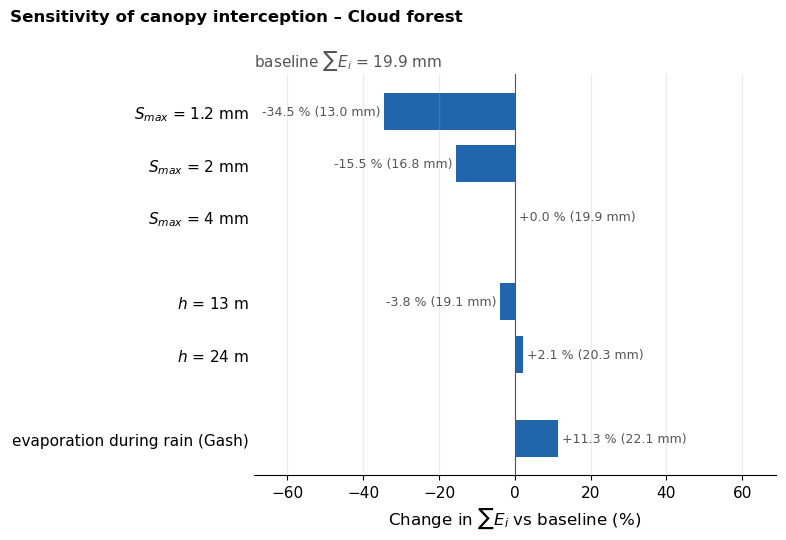

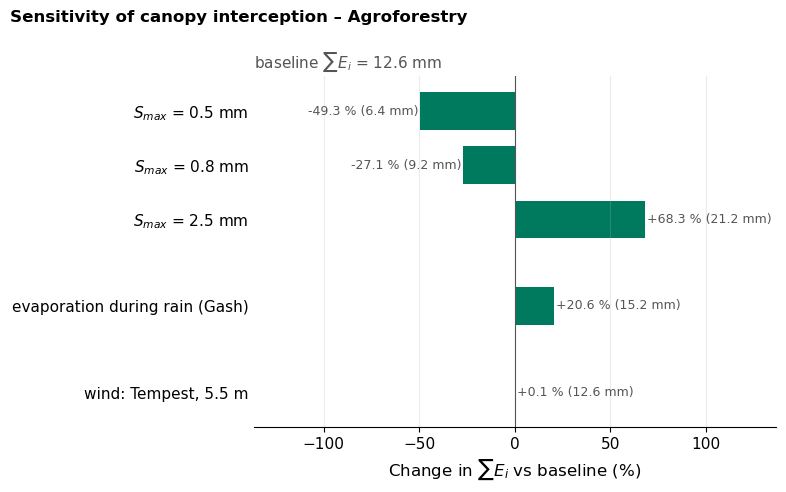

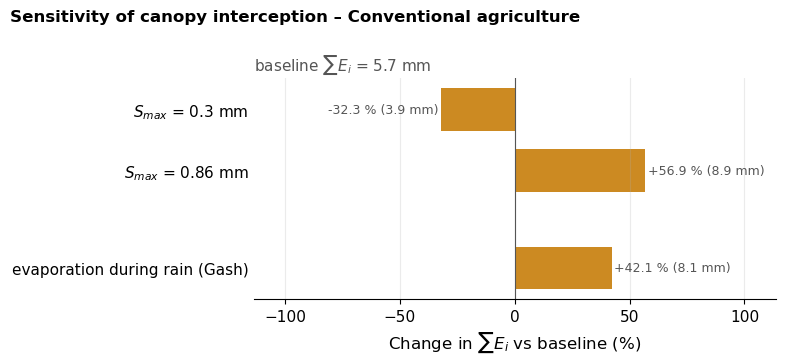

In [137]:
def summarize(plot, case, o, min_dry, base_Ei, S_max=None, h=None):
    _, ev = identify_events(o, min_dry, MIN_EVENT_MM)
    ev = ev[~ev.small] if not ev.empty else ev
    Ei = o.Ei.sum()
    return dict(plot=plot, case=case, hours=len(o), E0=o.E0_mm.sum(), Ei=Ei,
                Ei_pct_In=100 * Ei / o.In.sum(), Pe=o.Pe.sum(), error=o.error.sum(min_count=1),
                n_events=len(ev), Ei_per_event=ev.Ei.mean() if len(ev) else np.nan,
                dEi_pct=100 * (Ei - base_Ei) / base_Ei, min_dry_h=min_dry,
                S_max_mm=PARAMS[plot]["S_max_mm"] if S_max is None else S_max,
                h_m=PARAMS[plot]["canopy_height_m"] if h is None else h,
                ra_median=o.ra.median())


rows, wind_rows = [], []
for plot in PLOTS_TO_RUN:
    p, base = PARAMS[plot], results[plot]
    S_max, h0 = p["S_max_mm"], p["canopy_height_m"]
    base_Ei, n_h = base.Ei.sum(), len(base)
    rows.append(summarize(plot, "baseline", base, MIN_DRY[plot], base_Ei))

    runs = [(f"S_max = {s:g} mm", dict(S_max=s)) for s in S_MAX_VALUES.get(plot, []) if s != S_max]
    runs += [(f"h = {h:g} m", dict(h=h)) for h in H_VALUES.get(plot, []) if h != h0]
    runs.append(("evaporation during rain (Gash)", dict(evap_during_input=True)))
    if WIND_SENSITIVITY and p.get("wind_alt"):
        alt = p["wind_alt"]
        runs.append((f"wind: {alt['label']}", dict(wind=alt["source"], z_m=alt["height_m"])))
    for case, kw in runs:
        o = run_plot(plot, verbose=False, **kw)
        check_run(o, kw.get("S_max", S_max), kw.get("evap_during_input", EVAP_DURING_INPUT), f"{plot} {case}")
        assert len(o) == n_h, f"{plot} {case}: {len(o)} valid hours, baseline {n_h}"
        rows.append(summarize(plot, case, o, MIN_DRY[plot], base_Ei, kw.get("S_max"), kw.get("h")))
    for d in DRY_HOURS_CASES:                                   # events only: same run, other separation
        rows.append(summarize(plot, f"min dry period {d} h", base, d, base_Ei))

    # wind data sets: baseline vs alternative
    if WIND_SENSITIVITY and p.get("wind_alt"):
        x = DATA[plot].loc[base.index]                          # the valid hours of the runs
        r = x[["wind_ecmwf", "wind_column"]].corr().iloc[0, 1]
        ratio = x["wind_column"].mean() / x["wind_ecmwf"].mean()
        print(f"{plot}: ECMWF 100 m vs {p['wind_alt']['label']}: hourly r = {r:.2f}, "
              f"mean ratio local/ECMWF = {ratio:.2f}")
        for label, src, z in [(f"ECMWF, {p['wind_height_m']:g} m", p["wind_source"], p["wind_height_m"]),
                              (p["wind_alt"]["label"], p["wind_alt"]["source"], p["wind_alt"]["height_m"])]:
            o = run_plot(plot, wind=src, z_m=z, verbose=False)
            day = o.index.hour.isin(range(7, 18))
            wind_rows.append(dict(plot=plot, wind=label, z_m=z, wind_mean_ms=o.wind.mean(),
                                  wind_median_ms=o.wind.median(), at_wind_floor_pct=100 * (o.wind <= U_MIN).mean(),
                                  ra_median=o.ra.median(), ra_median_day=o.ra[day].median(),
                                  E0=o.E0_mm.sum(), Ei=o.Ei.sum(), dEi_pct=100 * (o.Ei.sum() - base_Ei) / base_Ei,
                                  r_hourly=r, mean_ratio_local_ecmwf=ratio, hours=len(o)))
            print(f"  {label}: median r_a {o.ra.median():.0f} s/m (daytime {o.ra[day].median():.0f} s/m)")

sens = pd.DataFrame(rows)
sens.round(4).to_csv(f"{OUTPUT_DIR}/sensitivity_all.csv", index=False)
display(sens.round(2))
if wind_rows:
    sens_wind = pd.DataFrame(wind_rows)
    sens_wind.round(4).to_csv(f"{OUTPUT_DIR}/sensitivity_wind.csv", index=False)
    display(sens_wind.round(2))

# ranges for the report: Ei over the S_max and h intervals (baseline included)
for plot in PLOTS_TO_RUN:
    s = sens[sens["plot"] == plot]
    for what, col, unit in [("S_max", "S_max_mm", "mm"), ("h", "h_m", "m")]:
        g = s[s.case.str.startswith(what) | (s.case == "baseline")]
        if len(g) > 1:
            print(f"{plot}: {what} = {g[col].min():g}–{g[col].max():g} {unit} -> "
                  f"Ei = {g.Ei.min():.2f}–{g.Ei.max():.2f} mm (baseline {s.loc[s.case == 'baseline', 'Ei'].iloc[0]:.2f} mm)")

# figures: one per plot, % change in sum Ei per model case (site colour; labels = % change and sum Ei).
# The minimum-dry-period cases change the events only: they are in sensitivity_all.csv, not plotted.
GREY = "#555555"
GROUPS = ["S_max", "h =", "evaporation", "wind"]


def case_label(c):
    if c.startswith("S_max"):
        return "$S_{max}$ = " + c.split("= ")[1]
    if c.startswith("h ="):
        return "$h$ = " + c.split("= ")[1]
    if c.startswith("evaporation"):
        return "evaporation during rain (Gash)"
    if c.startswith("wind"):
        return "wind: " + c.split(": ")[1]
    return c


for plot in PLOTS_TO_RUN:
    s = sens[sens["plot"] == plot].drop_duplicates("case").set_index("case")
    base_Ei = s.loc["baseline", "Ei"]
    model_cases = [c for c in s.index if c != "baseline" and not c.startswith("min dry")]
    rows_, y = [], 0
    for key in GROUPS:                                   # group the cases, with a gap between groups
        cs = [c for c in model_cases if c.startswith(key)]
        for c in cs:
            rows_.append((y, c)); y += 1
        if cs:
            y += 0.6
    fig, ax = plt.subplots(figsize=(8, 0.5 * y + 1.6))
    yy = [r[0] for r in rows_]
    v = np.array([s.loc[c, "dEi_pct"] for _, c in rows_])
    ax.barh(yy, v, height=0.7, color=SITE[plot]["primary"])
    for yv, (_, c), val in zip(yy, rows_, v):
        ax.text(val + (1 if val >= 0 else -1), yv, f"{val:+.1f} % ({s.loc[c, 'Ei']:.1f} mm)", va="center",
                ha="left" if val >= 0 else "right", fontsize=9, color=GREY)
    ax.axvline(0, color=GREY, lw=0.8)
    ax.set_yticks(yy, [case_label(c) for _, c in rows_]); ax.invert_yaxis()
    lim = max(10, np.nanmax(np.abs(v)) * 2.0)
    ax.set_xlim(-lim, lim)
    ax.set_xlabel(rf"Change in $\sum E_i$ vs baseline (%; baseline $\sum E_i$ = {base_Ei:.1f} mm)")
    ax.grid(axis="x", alpha=.25); ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    plt.tight_layout()
    fig.savefig(f"{OUTPUT_PREFIX}_{plot}_fig_sensitivity.png", dpi=200, bbox_inches="tight"); plt.show()


## 9. Figures

Colours: in the figures of one plot every **term** has its own colour (`TERM`, `LIM`: input blue, $TF+SF$
green, $S_i$ green, $S_{max}$ / modelled $TF+SF$ dark green, $E_0$ / $E_i$ orange, error red); the **site**
colours are used only when plots are compared (9.4–9.7).

9.1 Hourly bucket per plot (whole period + zoom): (a) input with observed and modelled $TF+SF$ — their
difference is the mismatch of the water balance (an error, not a process); (b) modelled $S_i$;
(c) $E_0$ and $E_i$, shaded by what limits $E_i$ · 9.2 cumulative partition · 9.3 budget: observed $TF$, $SF$,
modelled $E_i$, $\Delta S_i$ and the error; 9.3b the same as
modelled $P_e$, $E_i$, $\Delta S_i$ with $P_e$ split into observed $TF+SF$ and the error · 9.4 what limits $E_i$ · 9.5 events: apparent interception vs $E_i$ ·
9.6 diurnal cycle of mean evaporation ($E_0$, $E_i$) · 9.7 daily $E_i$ per plot.


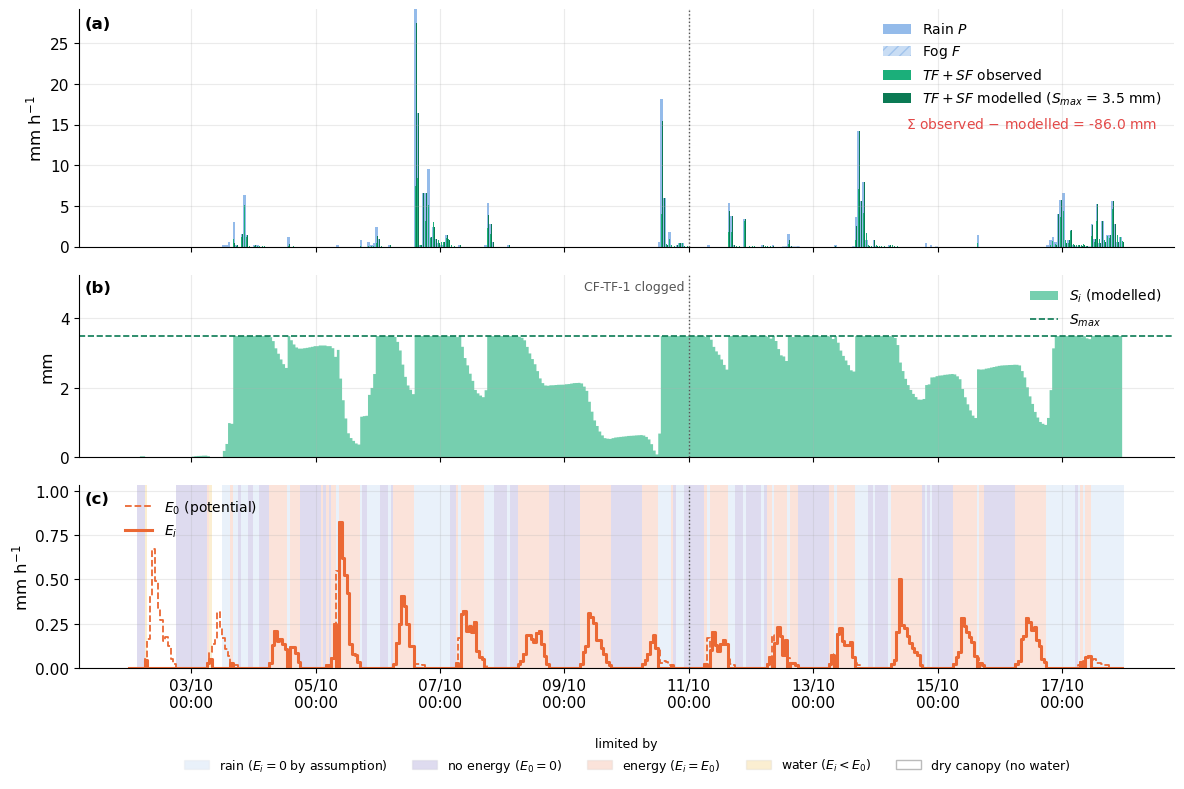

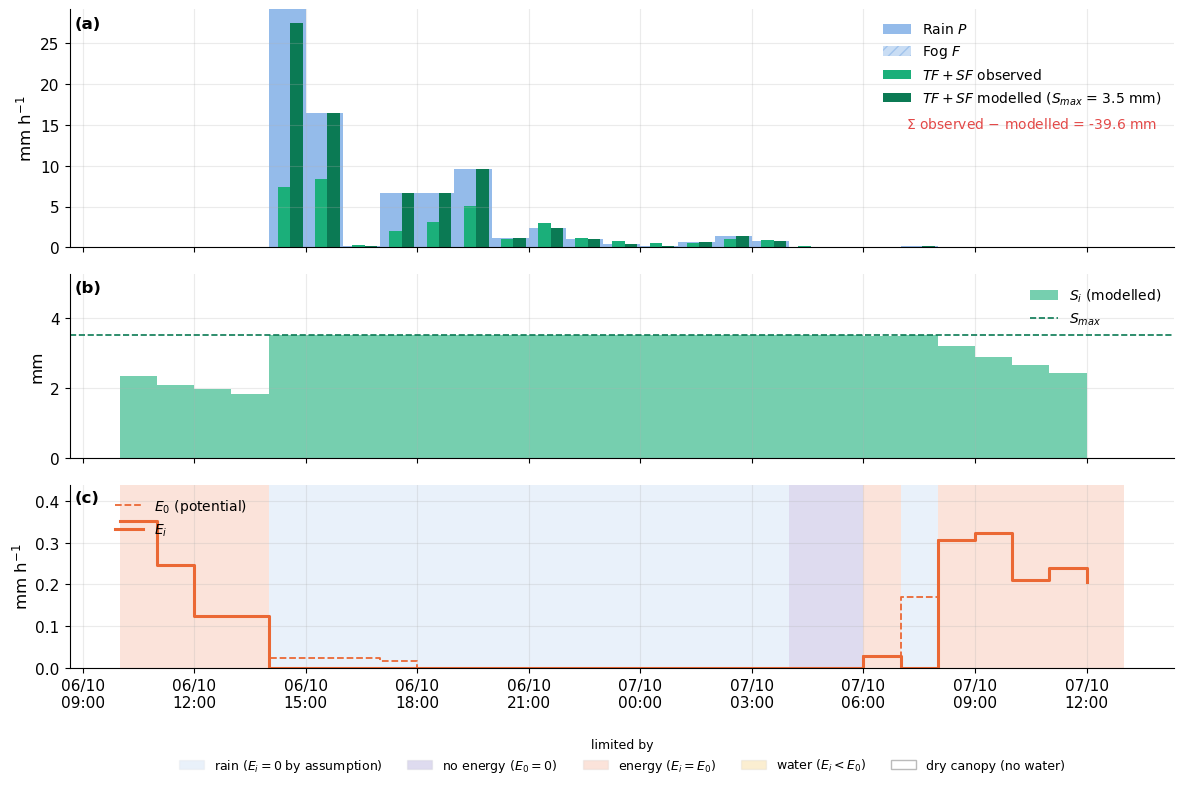

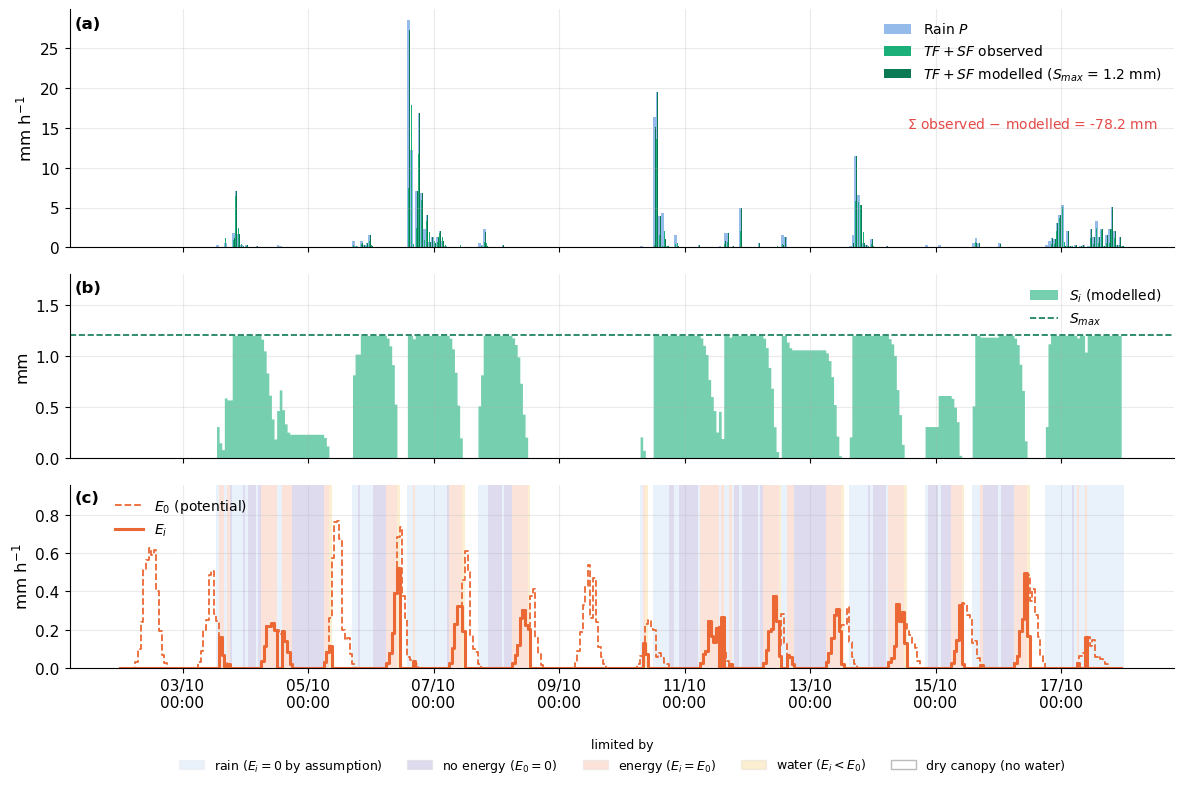

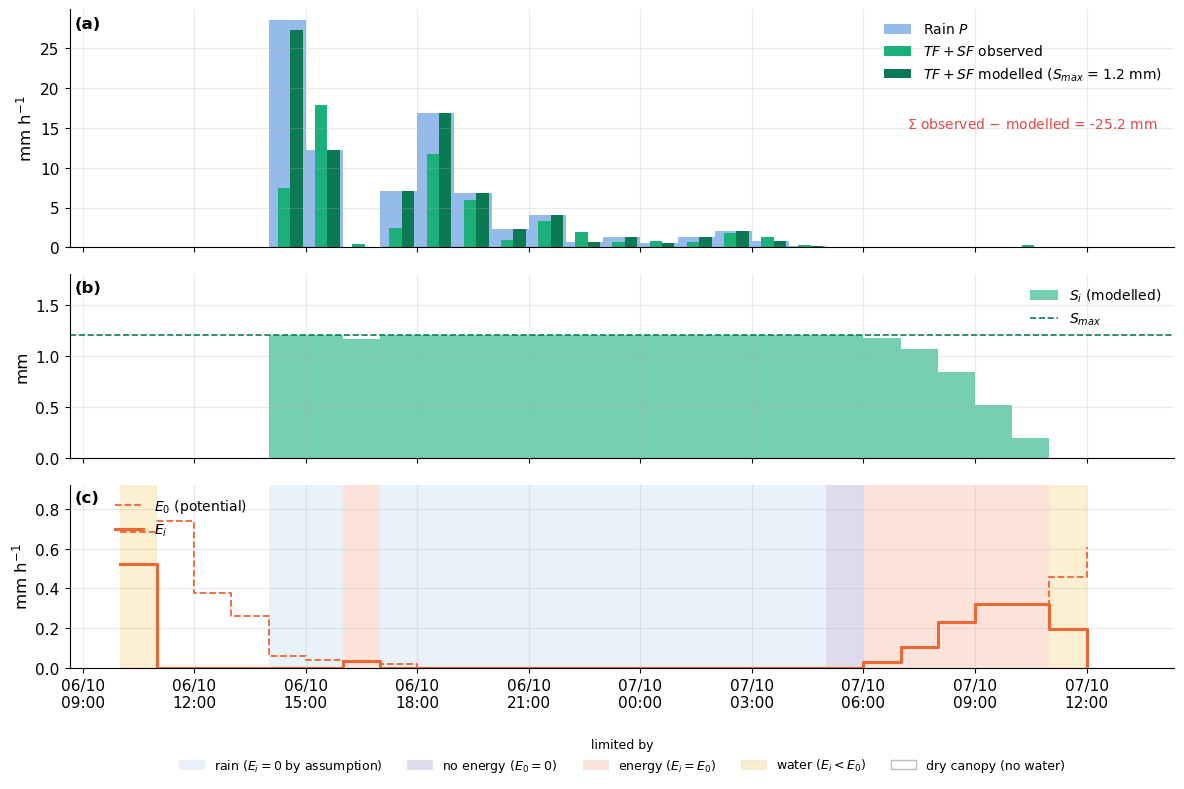

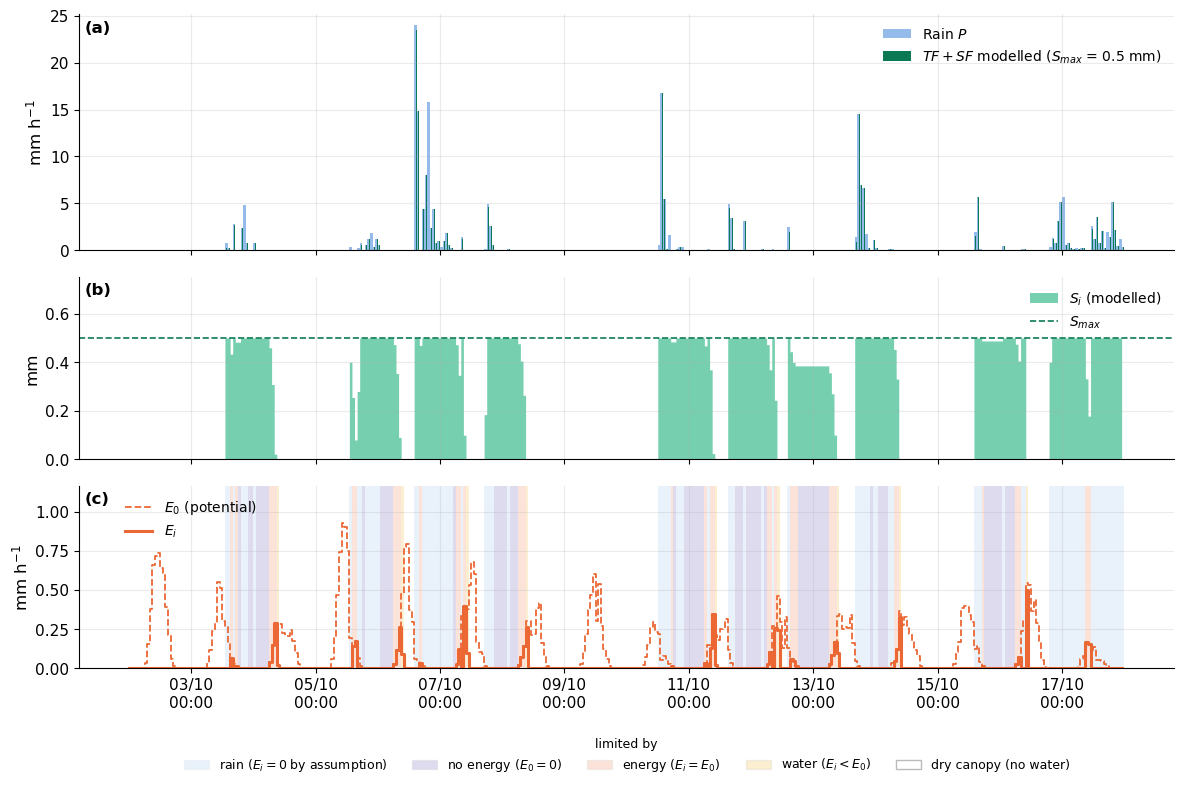

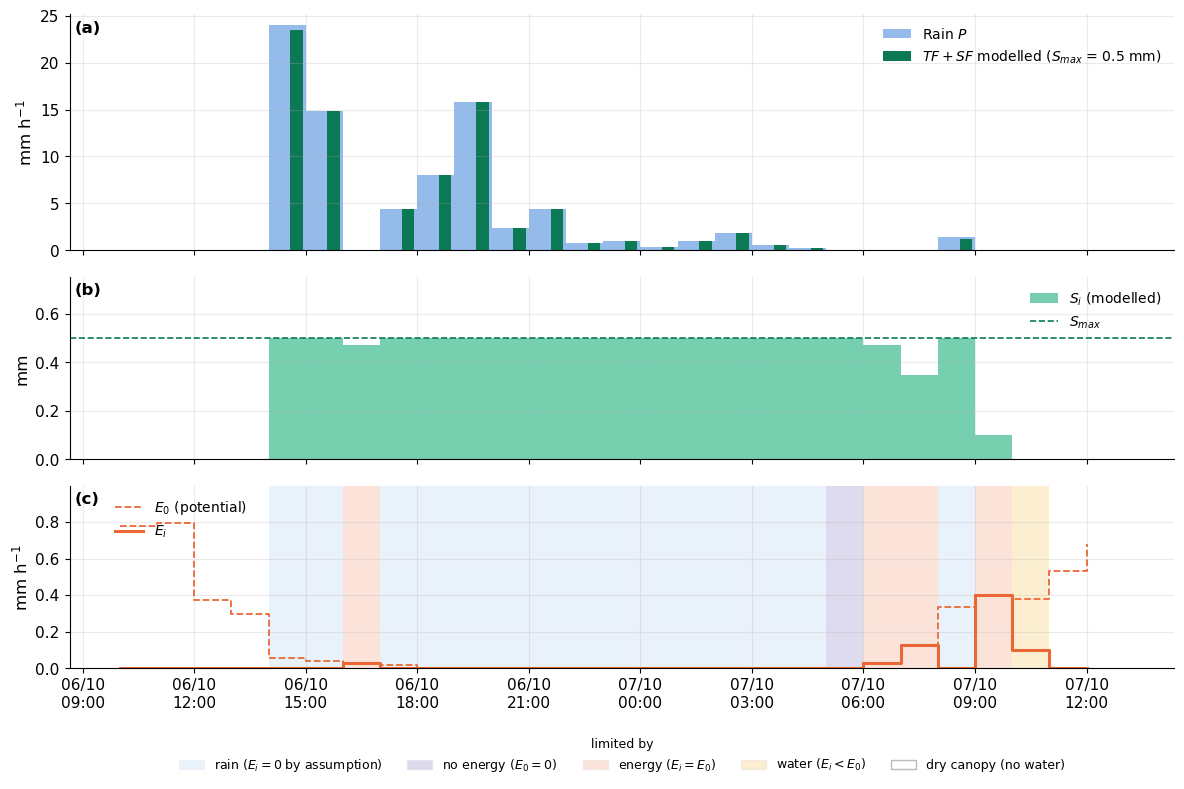

In [138]:
import textwrap
from matplotlib.colors import to_rgb
from matplotlib.legend_handler import HandlerTuple
from matplotlib.patches import Patch

# ---------------- colours ----------------
# One colour per TERM (same in every figure of one plot); site colours (cc_colors.SITE) only when plots are compared.
TERM = dict(In="#2a78d6",        # input P (+F), bars alpha 0.5
            TF="#1baf7a",        # TF+SF observed
            S="#1baf7a",         # S_i, alpha 0.6
            Smax="#0b7a54",      # S_max line (dashed)
            Pe="#0b7a54",        # TF+SF modelled (Pe)
            Ei="#eb6834",        # E0 (dashed) and Ei (solid)
            grey="#8a8a8a",
            err="#e34948",       # error (observed - modelled)
            zero="#555555")
LIM = {                                     # background colour, alpha, legend label
    "rain (no evaporation)": ("#2a78d6", .10, "rain ($E_i = 0$ by assumption)"),
    "no energy (E0 = 0)":    ("#4a3aa7", .18, "no energy ($E_0 = 0$)"),
    "energy (Ei = E0)":      ("#eb6834", .18, "energy ($E_i = E_0$)"),
    "water (Ei < E0)":       ("#eda100", .18, "water ($E_i < E_0$)"),
    "dry canopy (no water)": ("#ffffff", 1.0, "dry canopy (no water)"),
}


def lim_patch(key, alpha=None):
    c, a, lab = LIM[key]
    return Patch(facecolor=c, alpha=a if alpha is None else alpha, edgecolor="#bbbbbb", label=lab)


def text_color(c):
    r, g, b = to_rgb(c)
    return "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.6 else INK


def clean(ax):
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    ax.grid(alpha=.25)


sites = list(results)


# ---------- 9.1 hourly bucket: (a) input, observed vs modelled TF+SF, (b) S_i, (c) E0, Ei and what limits Ei ----------
# The difference between observed and modelled TF+SF is a mismatch of the water balance (an error), not a process.
def plot_bucket(t, plot, start=None, end=None):
    d = t.loc[start:end]
    S_max = PARAMS[plot]["S_max_mm"]
    has_meas = "error" in d and d.error.notna().any()
    w = 1 / 24                                                  # one hour in days
    fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True, gridspec_kw=dict(height_ratios=[1.3, 1, 1]))
    # (a) full period: cumulative input, observed and modelled TF+SF (the mismatch shows as steps at the storms);
    #     zoom: hourly bars
    pe_lab = f"$P_e$ modelled ($S_{{max}}$ = {S_max:g} mm)"
    if start is None:
        te = d.index + pd.Timedelta("1h")                      # cumulative at the end of each hour
        fog_in = PARAMS[plot]["fog"] and d.F.sum() > 0
        ax[0].plot(te, d.In.cumsum(), color=TERM["In"], lw=2, label="Input $P+F$" if fog_in else "Rain $P$")
        if has_meas:
            ax[0].plot(te, (d.TF + d.SF).fillna(0).cumsum(), color=TERM["TF"], lw=2, label="$TF+SF$ observed")
        ax[0].plot(te, d.Pe.cumsum(), color=TERM["Pe"], lw=2, ls="--", label=pe_lab)
        if has_meas:                                            # gap at the end of the record
            obs_end, pe_end = (d.TF + d.SF).sum(), d.Pe.sum()
            ax[0].annotate("", xy=(te[-1], obs_end), xytext=(te[-1], pe_end),
                           arrowprops=dict(arrowstyle="<->", color=TERM["err"], lw=1.2))
            last = slice(int(len(d) * 0.75), None)               # label between the two curves, last quarter
            y_lab = ((d.TF + d.SF).fillna(0).cumsum().iloc[last].mean() + d.Pe.cumsum().iloc[last].mean()) / 2
            ax[0].text(te[-1] - pd.Timedelta("3h"), y_lab,
                       rf"$\Sigma$ observed $-$ modelled = {obs_end - pe_end:+.1f} mm",
                       va="center", ha="right", fontsize=10, color=TERM["err"])
        ax[0].set_ylabel("Cumulative (mm)"); ax[0].set_ylim(0, None)
        ax[0].legend(loc="upper left", bbox_to_anchor=(0.03, 1), frameon=False, fontsize=10)
    else:
        ax[0].bar(d.index, d.P, width=w, align="edge", color=TERM["In"], alpha=.5, label="Rain $P$")
        if PARAMS[plot]["fog"] and d.F.sum() > 0:
            ax[0].bar(d.index, d.F, bottom=d.P, width=w, align="edge", color=TERM["In"], alpha=.25, hatch="///",
                      edgecolor=TERM["In"], lw=0, label="Fog $F$")
        if has_meas:
            ax[0].bar(d.index + pd.Timedelta("15min"), d.TF + d.SF, width=w / 3, align="edge", color=TERM["TF"],
                      label="$TF+SF$ observed")
        ax[0].bar(d.index + pd.Timedelta("35min"), d.Pe, width=w / 3, align="edge", color=TERM["Pe"], label=pe_lab)
        if has_meas:
            mism = (d.TF + d.SF).sum() - d.Pe.sum()
            ax[0].text(0.985, 0.55, rf"$\Sigma$ observed $-$ modelled = {mism:+.1f} mm", transform=ax[0].transAxes,
                       va="top", ha="right", fontsize=10, color=TERM["err"])
        ax[0].set_ylabel("mm h$^{-1}$"); ax[0].legend(loc="upper right", frameon=False, fontsize=10)
    if not has_meas:                                            # e.g. CA: no gauges, only the modelled P_e
        xy, ha = ((0.045, 0.74), "left") if start is None else ((0.985, 0.78), "right")   # below the legend
        ax[0].text(*xy, "no $TF$ / $SF$ measurements", transform=ax[0].transAxes,
                   va="top", ha=ha, fontsize=10, color=TERM["zero"])
    # (b) modelled canopy storage
    ax[1].fill_between(d.index, d.Si, step="post", color=TERM["S"], alpha=.6, lw=0, label="$S_i$ (modelled)")
    ax[1].axhline(S_max, ls="--", color=TERM["Smax"], lw=1.2, label="$S_{max}$")
    ax[1].set_ylim(0, S_max * 1.5); ax[1].set_ylabel("mm")
    ax[1].legend(loc="upper right", frameon=False, fontsize=10)
    # (c) E0, Ei and the limiting factor in each hour
    for ts, lab in d["limited_by"].items():
        c, a, _ = LIM[lab]
        if c != "#ffffff":
            ax[2].axvspan(ts, ts + pd.Timedelta("1h"), color=c, alpha=a, lw=0)
    ax[2].step(d.index, d.E0, where="post", ls="--", color=TERM["Ei"], lw=1.3, label="$E_0$ (potential)")
    ax[2].step(d.index, d.Ei, where="post", color=TERM["Ei"], lw=2.2, label="$E_i$")
    ax[2].set_ylabel("mm h$^{-1}$"); ax[2].set_ylim(0, max(d.E0.max(), 0.05) * 1.25)
    l1 = ax[2].legend(loc="upper left", bbox_to_anchor=(0.03, 1), frameon=False, fontsize=10)
    ax[2].add_artist(l1)
    ax[2].legend(handles=[lim_patch(k) for k in LIM], title="limited by", loc="upper center",
                 bbox_to_anchor=(0.5, -0.32), ncol=5, fontsize=9, title_fontsize=9, frameon=False)
    for t0, t1, lab in MARKS.get(plot, []):                     # e.g. CF-1-TF clogged: shaded in (a) and (b)
        t0, t1 = max(pd.Timestamp(t0), d.index.min()), min(pd.Timestamp(t1), d.index.max() + pd.Timedelta("1h"))
        if t0 < t1:
            for a in ax[:2]:
                a.axvspan(t0, t1, facecolor="none", edgecolor=TERM["grey"], hatch="///", lw=0, alpha=.45, zorder=0)
            ax[1].text(t0 + (t1 - t0) / 2, 0.97, lab, transform=ax[1].get_xaxis_transform(), ha="center", va="top",
                       fontsize=9, color=TERM["zero"], bbox=dict(fc="white", ec="none", alpha=.8, pad=1))
    for i, a in enumerate(ax):
        a.text(0.005, 0.97, f"({'abc'[i]})", transform=a.transAxes, va="top", fontweight="bold")
        clean(a)
    ax[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
    plt.tight_layout()
    tag = "" if start is None else f"_{pd.Timestamp(start):%m%d%H}"
    fig.savefig(f"{OUTPUT_PREFIX}_{plot}_bucket{tag}.png", dpi=200, bbox_inches="tight"); plt.show()


for plot, t in bucket_tables.items():
    plot_bucket(t, plot)
    plot_bucket(t, plot, *ZOOM)


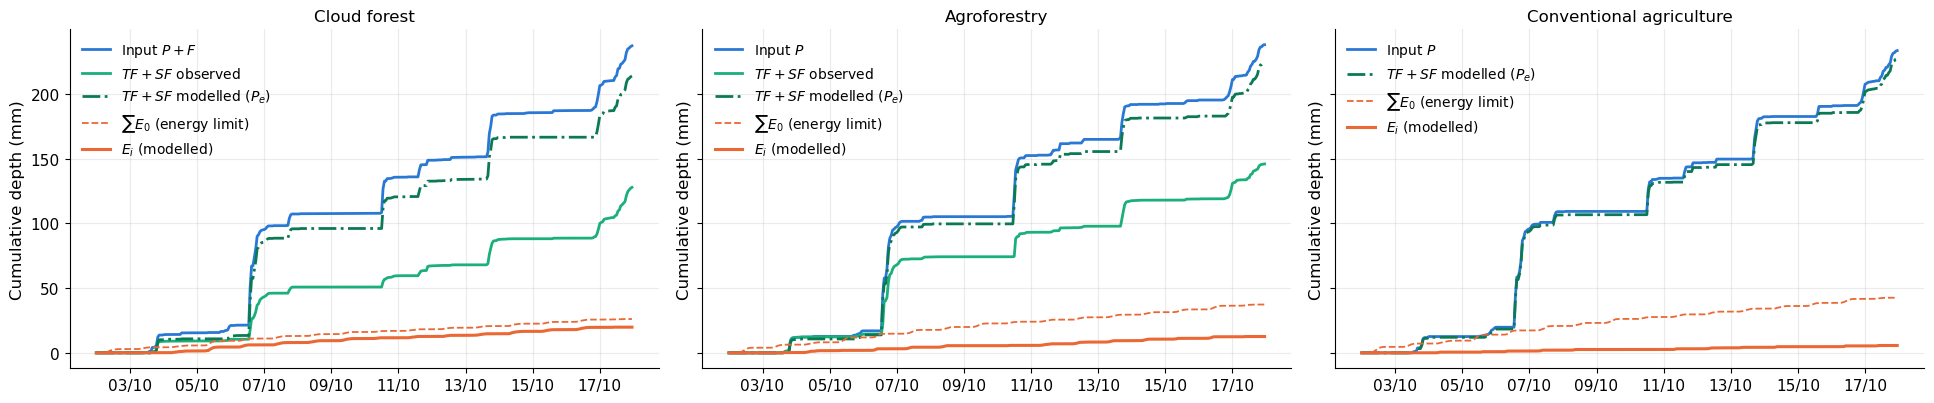

CF: TF + SF + Ei + dS + miss = 100.00 % of In
AF: TF + SF + Ei + dS + miss = 100.00 % of In
CA: Pe + Ei + dS = 100.00 % of In


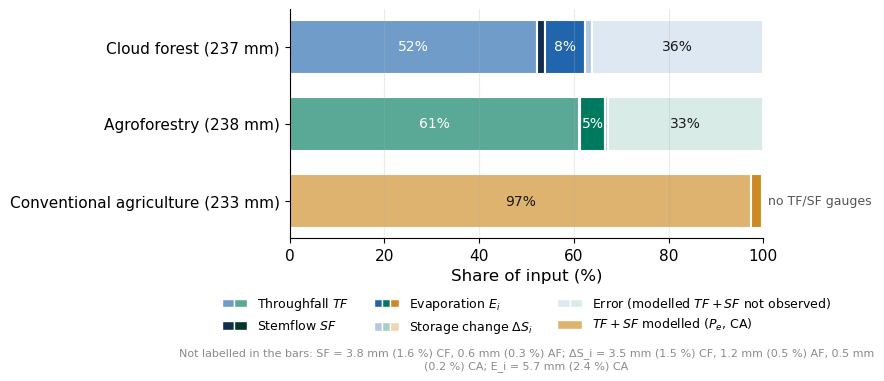

,In,Ei,dS,Pe,TF,SF,meas,error,miss,TF_%,SF_%,Ei_%,dS_%,Pe_%,meas_%,miss_%
CF,237.2,19.9,3.5,213.8,124.1,3.8,127.8,-86.0,86.0,52.3,1.6,8.4,1.5,90.1,53.9,36.2
AF,238.0,12.6,1.2,224.2,145.3,0.6,145.9,-78.2,78.2,61.1,0.3,5.3,0.5,94.2,61.3,32.9
CA,233.5,5.7,0.5,227.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.4,0.2,97.3,NaN,NaN


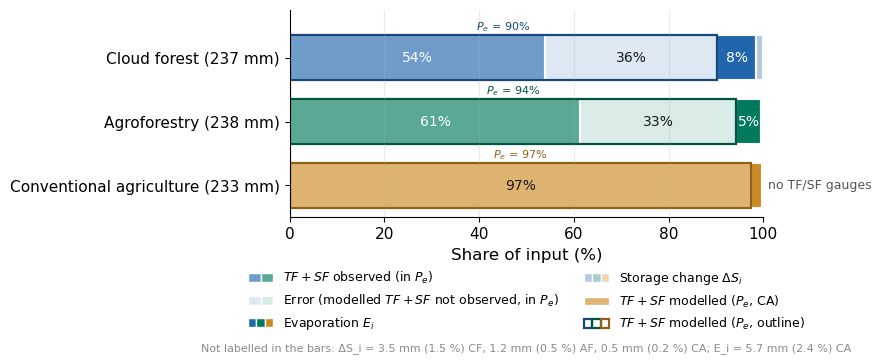

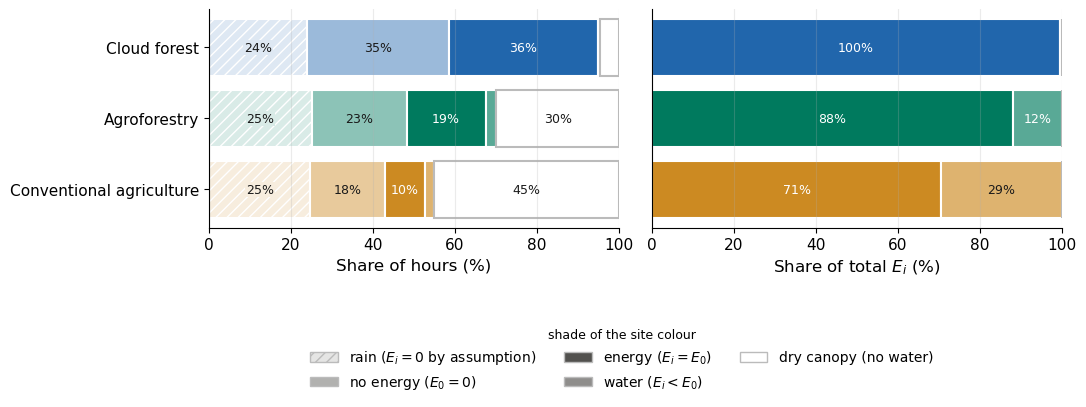

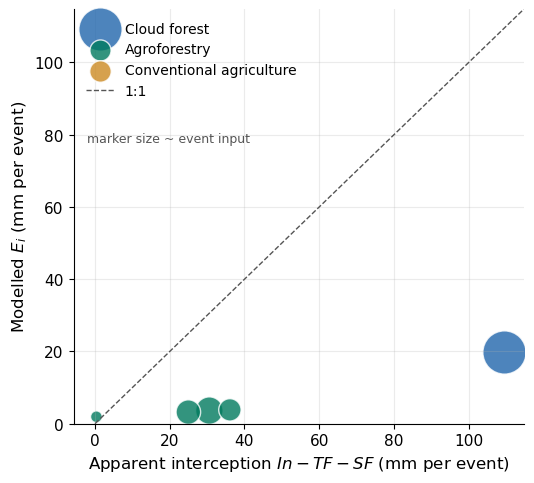

In [139]:
# ---------- 9.2 cumulative partition (one panel per plot, term colours) ----------
fig, axes = plt.subplots(1, len(sites), figsize=(6.5 * len(sites), 4.2), sharey=True, squeeze=False)
for ax, p in zip(axes[0], sites):
    o = results[p]
    ax.plot(o.index, o.In.cumsum(), color=TERM["In"], lw=2, label="Input $P+F$" if PARAMS[p]["fog"] else "Input $P$")
    if o.error.notna().any():
        ax.plot(o.index, (o.TF + o.SF).cumsum(), color=TERM["TF"], lw=2, label="$TF+SF$ observed")
    ax.plot(o.index, o.Pe.cumsum(), color=TERM["Pe"], lw=2, ls="-.", label="$TF+SF$ modelled ($P_e$)")
    ax.plot(o.index, o.E0_mm.cumsum(), color=TERM["Ei"], lw=1.3, ls="--", label=r"$\sum E_0$ (energy limit)")
    ax.plot(o.index, o.Ei.cumsum(), color=TERM["Ei"], lw=2.2, label=r"$E_i$ (modelled)")
    ax.set_xlabel(PARAMS[p]["name"])                            # site name below the panel (no titles)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m")); ax.set_ylabel("Cumulative depth (mm)")
    clean(ax); ax.legend(loc="upper left", frameon=False, fontsize=10)
plt.tight_layout(); fig.savefig(f"{OUTPUT_PREFIX}_fig_cumulative.png", dpi=200); plt.show()

# ---------- 9.3 budget: one bar per plot, % of input In = P + F (plots compared -> shades of the site colour) ----------
# gauges: TF + SF (observed) + Ei + dS_i + error = In, with error = Pe - (TF + SF) = -sum(error)
# CA (no gauges): Pe (modelled TF + SF) + Ei + dS_i = In
bud = pd.DataFrame({p: dict(In=o.In.sum(), Ei=o.Ei.sum(), dS=o.dSi_dt.sum(), Pe=o.Pe.sum(),
                            TF=o.TF.sum(min_count=1) if "TF" in o else np.nan,
                            SF=o.SF.sum(min_count=1) if "SF" in o else np.nan,
                            meas=(o.TF + o.SF).sum(min_count=1) if {"TF", "SF"} <= set(o) else np.nan,
                            error=o.error.sum(min_count=1))
                    for p, o in results.items()}).T
bud["miss"] = -bud.error                                         # Pe - (TF + SF)
BUD = {  # key: (colour from the site primary, legend label)
    "TF":   (lambda c: tint(c, 0.35), "Throughfall $TF$"),
    "SF":   (lambda c: shade(c, 0.55), "Stemflow $SF$"),
    "Pe":   (lambda c: tint(c, 0.35), "$TF+SF$ modelled ($P_e$, CA)"),
    "Ei":   (lambda c: c, "Evaporation $E_i$"),
    "dS":   (lambda c: tint(c, 0.65), r"Storage change $\Delta S_i$"),
    "miss": (lambda c: tint(c, 0.85), "Error (modelled $TF+SF$ not observed)"),
}
NOTE_NAME = dict(meas="TF+SF observed", TF="TF", SF="SF", Pe="P_e", Ei="E_i", dS="ΔS_i", miss="error")
fig, ax = plt.subplots(figsize=(9, 1.4 + 0.8 * len(bud)))
small = {}                                                       # segments < 4 %: listed in the note
for y, p in enumerate(bud.index):
    b, prim = bud.loc[p] / bud.loc[p, "In"] * 100, SITE[p]["primary"]
    gauges = pd.notna(b["meas"])
    keys = ["TF", "SF", "Ei", "dS", "miss"] if gauges else ["Pe", "Ei", "dS"]
    left = 0
    for key in keys:
        col = BUD[key][0](prim)
        ax.barh(y, b[key], left=left, color=col, edgecolor="white", linewidth=1.5, height=0.7)
        if abs(b[key]) >= 4:
            ax.text(left + b[key] / 2, y, f"{b[key]:.0f}%", ha="center", va="center", fontsize=10,
                    color=text_color(col))
        elif abs(bud.loc[p, key]) >= 0.05:                          # near-zero terms (e.g. dS_i at CA) not listed
            small.setdefault(key, []).append(f"{bud.loc[p, key]:.1f} mm ({b[key]:.1f} %) {p}")
        left += b[key]
    print(f"{p}: {' + '.join(keys)} = {left:.2f} % of In")
    assert abs(left - 100) < 1e-6, f"{p}: budget bar sums to {left:.3f} %"
    if not gauges:
        ax.text(left + 1, y, "no TF/SF gauges", va="center", ha="left", fontsize=9, color=TERM["zero"])
ax.set_yticks(range(len(bud)), [f"{PARAMS[p]['name']} ({bud.loc[p, 'In']:.0f} mm)" for p in bud.index])
ax.invert_yaxis()
ax.set_xlabel("Share of input (%)"); ax.set_xlim(0, 100)
clean(ax); ax.grid(axis="y", visible=False)
leg_keys = ["TF", "SF", "Ei", "dS", "miss", "Pe"]
leg_sites = {k: [p for p in bud.index if (k == "Pe") != pd.notna(bud.loc[p, "meas"])] if k in ["TF", "SF", "miss", "Pe"]
             else list(bud.index) for k in leg_keys}
handles = [tuple(Patch(fc=BUD[k][0](SITE[p]["primary"]), ec="white") for p in leg_sites[k]) for k in leg_keys]
ax.legend(handles, [BUD[k][1] for k in leg_keys], handler_map={tuple: HandlerTuple(ndivide=None, pad=0)},
          loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False, fontsize=9)
if small:
    note = "Not labelled in the bars: " + "; ".join(f"{NOTE_NAME[k]} = " + ", ".join(v) for k, v in small.items())
    ax.text(0.5, -0.2, "\n".join(textwrap.wrap(note, 120)), transform=ax.transAxes, ha="center", va="top",
            fontsize=8, color=TERM["grey"])
plt.tight_layout()
if small:                                                        # place the note below the legend
    fig.canvas.draw()
    lg = ax.get_legend().get_window_extent().transformed(ax.transAxes.inverted())
    ax.texts[-1].set_y(lg.y0 - 0.03)
fig.savefig(f"{OUTPUT_PREFIX}_fig_budget.png", dpi=200, bbox_inches="tight"); plt.show()
display(bud.assign(**{c + "_%": 100 * bud[c] / bud.In for c in ["TF", "SF", "Ei", "dS", "Pe", "meas", "miss"]}).round(1))

# ---------- 9.3b budget, model view: P_e + E_i + dS_i = 100 %; P_e split into observed TF + SF and the error ----------
fig, ax = plt.subplots(figsize=(9, 1.4 + 0.8 * len(bud)))
small = {}
for y, p in enumerate(bud.index):
    b, prim = bud.loc[p] / bud.loc[p, "In"] * 100, SITE[p]["primary"]
    gauges = pd.notna(b["meas"])
    # inside P_e: observed TF + SF, then the part the gauges did not catch (error); CA: P_e only
    segs = [("meas", tint(prim, 0.35)), ("miss", tint(prim, 0.85))] if gauges else [("Pe", tint(prim, 0.35))]
    segs += [("Ei", prim), ("dS", tint(prim, 0.65))]
    left = 0
    for key, col in segs:
        ax.barh(y, b[key], left=left, color=col, edgecolor="white", linewidth=1.5, height=0.7)
        if abs(b[key]) >= 4:
            ax.text(left + b[key] / 2, y, f"{b[key]:.0f}%", ha="center", va="center", fontsize=10,
                    color=text_color(col))
        elif abs(bud.loc[p, key]) >= 0.05:
            small.setdefault(key, []).append(f"{bud.loc[p, key]:.1f} mm ({b[key]:.1f} %) {p}")
        left += b[key]
    assert abs(left - 100) < 1e-6, f"{p}: model budget bar sums to {left:.3f} %"
    # outline of P_e (modelled TF + SF) around its two parts, with its total above the bar
    ax.barh(y, b["Pe"], left=0, color="none", edgecolor=shade(prim, 0.3), linewidth=1.6, height=0.7)
    ax.text(b["Pe"] / 2, y - 0.37, f"$P_e$ = {b['Pe']:.0f}%", ha="center", va="bottom", fontsize=8,
            color=shade(prim, 0.3))
    if not gauges:
        ax.text(left + 1, y, "no TF/SF gauges", va="center", ha="left", fontsize=9, color=TERM["zero"])
ax.set_yticks(range(len(bud)), [f"{PARAMS[p]['name']} ({bud.loc[p, 'In']:.0f} mm)" for p in bud.index])
ax.set_ylim(len(bud) - 0.5, -0.75)
ax.set_xlabel("Share of input (%)"); ax.set_xlim(0, 100)
clean(ax); ax.grid(axis="y", visible=False)
gauge_sites = [p for p in bud.index if pd.notna(bud.loc[p, "meas"])]
leg = [([tint(SITE[p]["primary"], 0.35) for p in gauge_sites], "$TF+SF$ observed (in $P_e$)"),
       ([tint(SITE[p]["primary"], 0.85) for p in gauge_sites], "Error (modelled $TF+SF$ not observed, in $P_e$)"),
       ([SITE[p]["primary"] for p in bud.index], "Evaporation $E_i$"),
       ([tint(SITE[p]["primary"], 0.65) for p in bud.index], r"Storage change $\Delta S_i$"),
       ([tint(SITE[p]["primary"], 0.35) for p in bud.index if p not in gauge_sites], "$TF+SF$ modelled ($P_e$, CA)")]
handles = [tuple(Patch(fc=c_, ec="white") for c_ in cols) for cols, _ in leg]
handles.append(tuple(Patch(fc="none", ec=shade(SITE[p]["primary"], 0.3), lw=1.6) for p in bud.index))
ax.legend(handles, [lab for _, lab in leg] + ["$TF+SF$ modelled ($P_e$, outline)"],
          handler_map={tuple: HandlerTuple(ndivide=None, pad=0)},
          loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False, fontsize=9)
if small:
    note = "Not labelled in the bars: " + "; ".join(f"{NOTE_NAME.get(k, k)} = " + ", ".join(v) for k, v in small.items())
    ax.text(0.5, -0.2, "\n".join(textwrap.wrap(note, 120)), transform=ax.transAxes, ha="center", va="top",
            fontsize=8, color=TERM["grey"])
plt.tight_layout()
if small:                                                        # place the note below the legend
    fig.canvas.draw()
    lg = ax.get_legend().get_window_extent().transformed(ax.transAxes.inverted())
    ax.texts[-1].set_y(lg.y0 - 0.03)
fig.savefig(f"{OUTPUT_PREFIX}_fig_budget_model.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------- 9.4 what limits Ei (plots compared -> shades of the site colour) ----------
SHADE = {"rain (no evaporation)": lambda c: tint(c, 0.85), "no energy (E0 = 0)": lambda c: tint(c, 0.55),
         "energy (Ei = E0)": lambda c: c, "water (Ei < E0)": lambda c: tint(c, 0.35),
         "dry canopy (no water)": lambda c: "#ffffff"}
fig, axes = plt.subplots(1, 2, figsize=(11, 1.8 + 0.8 * len(sites)), sharey=True, gridspec_kw=dict(wspace=0.08))
names = [PARAMS[p]["name"] for p in sites]
for ax, what in zip(axes, ["hours", "Ei"]):
    left = np.zeros(len(sites))
    for key in LIM:
        vals = np.array([100 * ((bucket_tables[p].limited_by == key).mean() if what == "hours"
                                else results[p].Ei[bucket_tables[p].limited_by == key].sum() / results[p].Ei.sum())
                         for p in sites])
        cols = [SHADE[key](SITE[p]["primary"]) for p in sites]
        dry = key.startswith("dry")
        ax.barh(names, vals, left=left, color=cols, edgecolor="#bbbbbb" if dry else "white", linewidth=1.5,
                hatch="///" if key.startswith("rain") else None)
        for i, (v, l, c) in enumerate(zip(vals, left, cols)):
            if v >= 5:
                ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, color=text_color(c),
                        bbox=dict(fc=c, ec="none", pad=0.5) if key.startswith("rain") else None)
        left += vals
    ax.set_xlabel("Share of hours (%)" if what == "hours" else r"Share of total $E_i$ (%)")
    ax.set_xlim(0, 100); clean(ax); ax.grid(axis="y", visible=False)
axes[0].invert_yaxis(); axes[1].tick_params(axis="y", length=0)
fig.legend(handles=[Patch(fc=SHADE[k](INK2), ec="#bbbbbb", hatch="///" if k.startswith("rain") else None,
                          label=LIM[k][2]) for k in LIM],
           loc="lower center", ncol=3, frameon=False, fontsize=10, bbox_to_anchor=(0.5, -0.06),
           title="shade of the site colour", title_fontsize=9)
fig.subplots_adjust(bottom=0.36)
fig.savefig(f"{OUTPUT_PREFIX}_fig_limitation.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------- 9.5 events: apparent interception vs modelled Ei (plots compared -> site colours) ----------
fig, ax = plt.subplots(figsize=(5.5, 5))
mx = 0.1
for p in sites:
    ev = events_all[p]
    if ev.empty or "I_measured" not in ev:
        continue
    ev = ev[~ev.small]
    ax.scatter(ev.I_measured, ev.Ei, s=20 + 4 * ev.In, color=SITE[p]["primary"], alpha=.8,
               edgecolor="white", linewidth=1, label=PARAMS[p]["name"])
    mx = max(mx, ev.I_measured.max(), ev.Ei.max())
ax.plot([0, mx * 1.05], [0, mx * 1.05], color=TERM["zero"], lw=1, ls="--", label="1:1")
ax.set_xlabel("Apparent interception $In - TF - SF$ (mm per event)"); ax.set_ylabel("Modelled $E_i$ (mm per event)")
ax.set_xlim(min(0, ax.get_xlim()[0]), mx * 1.05); ax.set_ylim(0, mx * 1.05)
clean(ax); ax.legend(frameon=False, loc="upper left", fontsize=10)
ax.text(0.03, 0.68, "marker size ~ event input", transform=ax.transAxes, fontsize=9, color=TERM["zero"])
plt.tight_layout(); fig.savefig(f"{OUTPUT_PREFIX}_fig_events.png", dpi=200); plt.show()


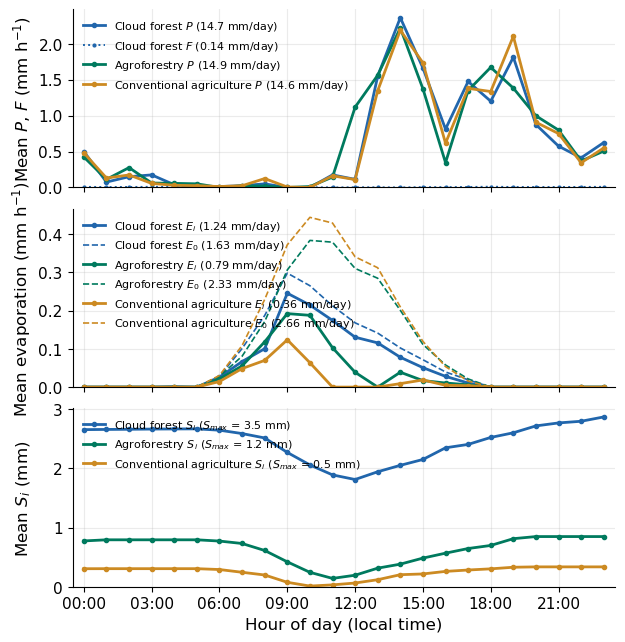

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
P_CF,5.00e-01,7.50e-02,1.50e-01,1.75e-01,3.80e-02,1.20e-02,0.01,2.50e-02,5.00e-02,0.00e+00,...,2.36e+00,1.66e+00,8.12e-01,1.48e+00,1.20,1.81e+00,8.75e-01,5.75e-01,4.13e-01,6.25e-01
F_CF,8.00e-03,6.00e-03,7.00e-03,8.00e-03,6.00e-03,9.00e-03,0.01,9.00e-03,2.00e-03,3.00e-03,...,0.00e+00,4.00e-03,4.00e-03,6.00e-03,0.01,6.00e-03,6.00e-03,6.00e-03,7.00e-03,8.00e-03
E0_CF,0.00e+00,0.00e+00,0.00e+00,0.00e+00,1.00e-03,0.00e+00,0.03,1.01e-01,1.87e-01,2.98e-01,...,1.02e-01,7.10e-02,3.90e-02,1.90e-02,0.00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00
Ei_CF,0.00e+00,0.00e+00,0.00e+00,0.00e+00,1.00e-03,0.00e+00,0.03,6.70e-02,1.00e-01,2.45e-01,...,7.80e-02,5.10e-02,2.80e-02,1.10e-02,0.00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00
Si_CF,2.66e+00,2.66e+00,2.66e+00,2.67e+00,2.67e+00,2.67e+00,2.65,2.59e+00,2.52e+00,2.27e+00,...,2.05e+00,2.15e+00,2.35e+00,2.41e+00,2.52,2.60e+00,2.72e+00,2.77e+00,2.80e+00,2.87e+00
P_AF,4.24e-01,1.13e-01,2.76e-01,6.20e-02,5.70e-02,5.10e-02,0.00,2.40e-02,1.90e-02,0.00e+00,...,2.22e+00,1.37e+00,3.46e-01,1.35e+00,1.67,1.38e+00,9.97e-01,7.99e-01,3.68e-01,5.06e-01
F_AF,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00,0.00e+00,0.00e+00,0.00e+00,...,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00
E0_AF,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.03,8.10e-02,1.71e-01,3.06e-01,...,2.01e-01,1.11e-01,5.80e-02,2.10e-02,0.00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00
Ei_AF,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.02,5.50e-02,1.18e-01,1.92e-01,...,3.90e-02,1.70e-02,1.10e-02,6.00e-03,0.00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00
Si_AF,7.74e-01,7.94e-01,7.94e-01,7.94e-01,7.94e-01,7.94e-01,0.77,7.31e-01,6.13e-01,4.21e-01,...,3.82e-01,4.84e-01,5.68e-01,6.46e-01,0.70,8.13e-01,8.48e-01,8.48e-01,8.48e-01,8.48e-01


In [140]:
# ---------- 9.6 diurnal cycle of mean evaporation (E0, Ei); the table keeps P, F, E0, Ei, S_i ----------
# mean per hour of day over all valid hours; plotted at the start of the hour (09:00 = 09:00-10:00)
VARS = [("P", "P"), ("F", "F"), ("E0", "E0_mm"), ("Ei", "Ei"), ("Si", "Si")]
diurnal = pd.DataFrame({f"{k}_{p}": results[p][col].groupby(results[p].index.hour).mean()
                        for p in sites for k, col in VARS}).reindex(range(24))
diurnal.index.name = "hour"
diurnal.round(4).to_csv(f"{OUTPUT_PREFIX}_diurnal.csv")

fig, ax = plt.subplots(figsize=(7, 3.6))                     # mean evaporation only (E_i and E_0)
for p in sites:
    col, o = SITE[p]["primary"], results[p]
    n_days = len(o) / 24                                    # days with data
    ax.plot(diurnal.index, diurnal[f"Ei_{p}"], color=col, lw=2, marker="o", ms=3,
            label=f"{PARAMS[p]['name']} $E_i$ ({o.Ei.sum() / n_days:.2f} mm/day)")
    ax.plot(diurnal.index, diurnal[f"E0_{p}"], color=col, lw=1.2, ls="--",
            label=f"{PARAMS[p]['name']} $E_0$ ({o.E0_mm.sum() / n_days:.2f} mm/day)")
ax.set_ylabel("Mean evaporation (mm h$^{-1}$)")
ax.set_ylim(0, None); clean(ax)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)   # outside: keeps the peaks free
ax.set_xticks(range(0, 24, 3), [f"{k:02d}:00" for k in range(0, 24, 3)]); ax.set_xlim(-0.5, 23.5)
ax.set_xlabel("Hour of day (local time)")
fig.savefig(f"{OUTPUT_PREFIX}_fig_diurnal.png", dpi=200, bbox_inches="tight"); plt.show()
display(diurnal.round(3).T)

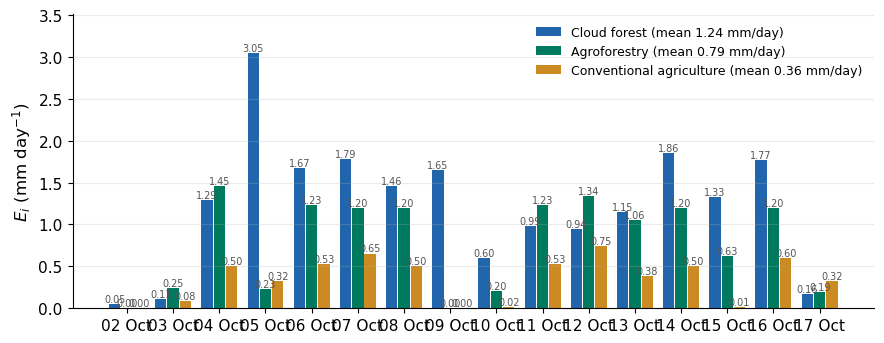

Timestamp,2026-10-02,2026-10-03,2026-10-04,2026-10-05,2026-10-06,2026-10-07,2026-10-08,2026-10-09,2026-10-10,2026-10-11,2026-10-12,2026-10-13,2026-10-14,2026-10-15,2026-10-16,2026-10-17
CF,0.05,0.11,1.29,3.05,1.67,1.79,1.46,1.65,0.60,0.99,0.94,1.15,1.86,1.33,1.77,0.16
AF,0.00,0.25,1.45,0.23,1.23,1.20,1.20,0.00,0.20,1.23,1.34,1.06,1.20,0.63,1.20,0.19
CA,0.00,0.08,0.50,0.32,0.53,0.65,0.50,0.00,0.02,0.53,0.75,0.38,0.50,0.01,0.60,0.32


In [141]:
# ---------- 9.7 daily canopy evaporation per plot ----------
# full days only (24 h of data at every plot)
daily_Ei = pd.DataFrame({p: results[p].Ei.resample("D").sum() for p in sites})
n_h = pd.DataFrame({p: results[p].Ei.resample("D").count() for p in sites})
daily_Ei = daily_Ei[(n_h == 24).all(axis=1)]
daily_Ei.round(3).to_csv(f"{OUTPUT_PREFIX}_daily_Ei.csv")

x, bw = np.arange(len(daily_Ei)), 0.8 / len(sites)
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, p in enumerate(sites):
    xs = x + (i - (len(sites) - 1) / 2) * bw
    ax.bar(xs, daily_Ei[p], width=bw * 0.92, color=SITE[p]["primary"],
           label=f"{PARAMS[p]['name']} (mean {daily_Ei[p].mean():.2f} mm/day)")
    for xx, v in zip(xs, daily_Ei[p]):
        ax.text(xx, v, f"{v:.2f}", ha="center", va="bottom", fontsize=7, color="#555")
ax.set_xticks(x, [f"{d:%d %b}" for d in daily_Ei.index])
ax.set_ylabel("$E_i$ (mm day$^{-1}$)"); ax.set_ylim(0, daily_Ei.values.max() * 1.15)
clean(ax); ax.grid(axis="x", visible=False); ax.legend(frameon=False, loc="upper right", fontsize=9)
plt.tight_layout(); fig.savefig(f"{OUTPUT_PREFIX}_fig_daily_Ei.png", dpi=200); plt.show()
display(daily_Ei.round(2).T)

In [ ]:
# ---------- 9.8 CF and AF: fraction of rainfall reaching the ground per rain intensity class ----------
# rain hours only (P > 0); fraction = sum(TF + SF) / sum(P) (measured) and sum(P_e) / sum(P) (modelled)
INTENSITY_BINS   = [0, 1, 2, 5, 10, np.inf]                 # mm h-1, lower bound included
INTENSITY_LABELS = ["<1", "1–2", "2–5", "5–10", ">10"]
def intensity_table(plot):
    """per rain intensity class: hours, P, measured TF+SF, P_e, fractions of P and error (obs - P_e)"""
    o = results[plot]
    r = o[o.P > 0].copy()
    r["cls"] = pd.cut(r.P, INTENSITY_BINS, labels=INTENSITY_LABELS, right=False)
    g = r.assign(meas=r.TF + r.SF).groupby("cls", observed=False)
    t = pd.DataFrame({"n_hours": g.size(), "P_mm": g.P.sum(), "TF_SF_mm": g.meas.sum(), "Pe_mm": g.Pe.sum()})
    t["frac_TF_SF"] = t.TF_SF_mm / t.P_mm
    t["frac_Pe"] = t.Pe_mm / t.P_mm
    t["error_mm"] = t.TF_SF_mm - t.Pe_mm                                # observed - modelled
    t.index.name = "P_class_mm_h"
    assert t.n_hours.sum() == len(r) and abs(t.P_mm.sum() - r.P.sum()) < 1e-9
    return t


def plot_intensity(ax, t, plot, pe_label):
    """grouped bars (measured = site secondary, modelled = site primary), n and error above each class"""
    xi, bw = np.arange(len(t)), 0.38
    ax.bar(xi - bw / 2, t.frac_TF_SF, bw * 0.95, color=SITE[plot]["secondary"], label="$TF+SF$ observed")
    ax.bar(xi + bw / 2, t.frac_Pe, bw * 0.95, color=SITE[plot]["primary"], label=pe_label)
    for x, row in zip(xi, t.itertuples()):                  # n hours and error (obs - P_e) just above the axes
        ax.text(x, 1.01, f"n = {row.n_hours} h\n{row.error_mm:+.1f} mm", ha="center", va="bottom",
                transform=ax.get_xaxis_transform(),
                fontsize=8, color=TERM["err"] if abs(row.error_mm) >= 0.05 else TERM["grey"])
    ax.set_xticks(xi, INTENSITY_LABELS)
    ax.set_xlabel(r"Rain intensity class $P$ (mm h$^{-1}$)")
    ax.set_ylim(0, 1.1); ax.set_yticks(np.arange(0, 1.01, 0.2))
    clean(ax); ax.grid(axis="x", visible=False)


for p in [q for q in ["CF", "AF"] if q in results]:            # one figure per plot (no title)
    t = intensity_table(p)
    t.round(3).to_csv(f"{OUTPUT_PREFIX}_{p}_intensity.csv")
    display(t.round(2))
    fig, ax = plt.subplots(figsize=(7, 4))      # site colours: measured = secondary, modelled = primary
    plot_intensity(ax, t, p, f"$P_e$ modelled ($S_{{max}}$ = {PARAMS[p]['S_max_mm']:g} mm)")
    ax.set_ylabel("Fraction of $P$ reaching the ground")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False, fontsize=9)
    plt.tight_layout()
    fig.savefig(f"{OUTPUT_PREFIX}_{p}_intensity.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------- 9.9 CF and AF side by side: (a) CF, (b) AF; same classes and y-axis ----------
INT_PLOTS = [p for p in ["CF", "AF"] if p in results]
int_tabs = {p: intensity_table(p) for p in INT_PLOTS}
pd.concat(int_tabs, names=["plot"]).round(3).to_csv(f"{OUTPUT_PREFIX}_intensity_CF_AF.csv")
display(pd.concat(int_tabs, names=["plot"]).round(2))
fig, axs = plt.subplots(1, len(INT_PLOTS), figsize=(6 * len(INT_PLOTS), 4.4), sharey=True, squeeze=False)
for k, (ax, p) in enumerate(zip(axs[0], INT_PLOTS)):
    plot_intensity(ax, int_tabs[p], p, "$P_e$ modelled")
    ax.set_title(f"({'ab'[k]}) {PARAMS[p]['name']} ($S_{{max}}$ = {PARAMS[p]['S_max_mm']:g} mm)", loc="left", pad=30)   # above the n / error row
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False, fontsize=9)
axs[0][0].set_ylabel("Fraction of $P$ reaching the ground")
plt.tight_layout()
fig.savefig(f"{OUTPUT_PREFIX}_intensity_CF_AF.png", dpi=200, bbox_inches="tight"); plt.show()


## 10. Export (all in `outputs_v2/`)

- `…_{plot}_hourly.csv`: all model variables (incl. `P`, `F`, `Ei`, `dSi_dt`, `Pe`, `error`, `S_wb`).
- `…_{plot}_events.csv`: event table.
- `…_{plot}_WB_hourly.csv` / `_WB_daily.csv`: canopy terms per hour / day.
  Check: `In = Ei + dS_canopy + Pe` every hour.
- `{plot}_interception_terms.csv`: totals over the run for the water-balance script
  (it computes $I_{net} = P + F - E_i - E_{veg} - E_{epi} - \Delta S$ as the residual).

In [142]:
for plot, out in results.items():
    out.to_csv(f"{OUTPUT_PREFIX}_{plot}_hourly.csv")
    if not events_all[plot].empty:
        events_all[plot].to_csv(f"{OUTPUT_PREFIX}_{plot}_events.csv", index=False)

    wb = pd.DataFrame(index=out.index)
    wb["In_mm"], wb["P_mm"], wb["F_mm"] = out.In, out.P, out.F
    wb["TF_mm"], wb["SF_mm"] = out.get("TF"), out.get("SF")
    wb["Ei_mm"] = out.Ei
    wb["S_canopy_mm"] = out.Si
    wb["dS_canopy_mm"] = out.dSi_dt
    wb["Pe_mm"] = out.Pe
    wb["error_mm"] = out.error
    wb["E0_mm"] = out.E0_mm
    err = (wb.In_mm - (wb.Ei_mm + wb.dS_canopy_mm + wb.Pe_mm)).abs().max()
    wb.round(4).to_csv(f"{OUTPUT_PREFIX}_{plot}_WB_hourly.csv")
    daily = wb.drop(columns="S_canopy_mm").resample("D").sum(min_count=1)
    daily.round(3).to_csv(f"{OUTPUT_PREFIX}_{plot}_WB_daily.csv")

    terms = dict(plot=plot, start=out.index.min(), end=out.index.max(), hours=len(out),
                 P_mm=out.P.sum(), F_mm=out.F.sum(), In_mm=out.In.sum(), Ei_mm=out.Ei.sum(),
                 dS_canopy_mm=out.dSi_dt.sum(), Pe_mm=out.Pe.sum(),
                 TF_mm=out["TF"].sum(min_count=1) if "TF" in out else np.nan,
                 SF_mm=out["SF"].sum(min_count=1) if "SF" in out else np.nan,
                 TF_SF_measured_mm=(out.TF + out.SF).sum(min_count=1) if {"TF", "SF"} <= set(out) else np.nan,
                 error_mm=out.error.sum(min_count=1), E0_mm=out.E0_mm.sum())
    pd.DataFrame([terms]).round(4).to_csv(f"{OUTPUT_DIR}/{plot}_interception_terms.csv", index=False)
    print(f"{PARAMS[plot]['name']}: WB closure error max = {err:.1e} mm; saved hourly, events, WB_hourly, "
          f"WB_daily, interception_terms")
    display(pd.DataFrame([terms]).round(2))

Cloud forest: WB closure error max = 3.6e-15 mm; saved hourly, events, WB_hourly, WB_daily, interception_terms


,plot,start,end,hours,P_mm,F_mm,In_mm,Ei_mm,dS_canopy_mm,Pe_mm,TF_mm,SF_mm,TF_SF_measured_mm,error_mm,E0_mm
0,CF,2026-10-02,2026-10-17 23:00:00,384,235.0,2.17,237.17,19.86,3.5,213.81,124.05,3.78,127.84,-85.97,26.13


Agroforestry: WB closure error max = 8.9e-16 mm; saved hourly, events, WB_hourly, WB_daily, interception_terms


,plot,start,end,hours,P_mm,F_mm,In_mm,Ei_mm,dS_canopy_mm,Pe_mm,TF_mm,SF_mm,TF_SF_measured_mm,error_mm,E0_mm
0,AF,2026-10-02,2026-10-17 23:00:00,384,238.0,0.0,238.0,12.62,1.2,224.18,145.31,0.63,145.93,-78.25,37.33


Conventional agriculture: WB closure error max = 4.4e-16 mm; saved hourly, events, WB_hourly, WB_daily, interception_terms


,plot,start,end,hours,P_mm,F_mm,In_mm,Ei_mm,dS_canopy_mm,Pe_mm,TF_mm,SF_mm,TF_SF_measured_mm,error_mm,E0_mm
0,CA,2026-10-02,2026-10-17 23:00:00,384,233.47,0.0,233.47,5.7,0.5,227.27,NaN,NaN,NaN,NaN,42.59


## 11. Checks

In [143]:
for plot, out in results.items():
    S_max = PARAMS[plot]["S_max_mm"]
    rain_Ei = out.Ei[out.P > 0].sum()
    print(f"{plot}: balance (max per segment) {segment_balance(out):.1e} mm | S_i in [{out.Si.min():.3f}, "
          f"{out.Si.max():.3f}] (S_max {S_max:g}) | Ei in rain hours {rain_Ei:.3g} mm | "
          f"valid hours {len(out)} (all sensitivity runs: {sorted(set(sens.loc[sens['plot'] == plot, 'hours']))})")
    check_run(out, S_max, EVAP_DURING_INPUT, plot)
    assert set(sens.loc[sens["plot"] == plot, "hours"]) == {len(out)}
print("all checks passed")

CF: balance (max per segment) 3.6e-14 mm | S_i in [0.000, 3.500] (S_max 3.5) | Ei in rain hours 0 mm | valid hours 384 (all sensitivity runs: [384])
AF: balance (max per segment) 2.9e-15 mm | S_i in [0.000, 1.200] (S_max 1.2) | Ei in rain hours 0 mm | valid hours 384 (all sensitivity runs: [384])
CA: balance (max per segment) 6.2e-15 mm | S_i in [0.000, 0.500] (S_max 0.5) | Ei in rain hours 0 mm | valid hours 384 (all sensitivity runs: [384])
all checks passed
